# Deepfake Face Detection: CNN dengan Multi-Head Self-Attention

**Final Project · Data Science & AI Machine Learning · Dibimbing**
Disusun oleh: Farrel

Notebook ini mengerjakan Final Project secara end-to-end mengikuti panduan 8 langkah pada guideline. Topiknya: **mendeteksi wajah sintetis (buatan AI) vs wajah asli dari sebuah foto** menggunakan deep learning.

| Langkah di Guideline | Bagian di Notebook | Keterangan |
|---|---|---|
| 1. Identifikasi Masalah Bisnis | Bagian 1 | Di notebook ini |
| 2. Metodologi Penelitian & Dataset | Bagian 2 – 4 | Di notebook ini |
| 3. Data Preprocessing | Bagian 5 | Di notebook ini |
| 4. Exploratory Data Analysis (EDA) | Bagian 6 | Di notebook ini |
| 5. Fine-Tuning & Evaluasi Model | Bagian 7 – 8 | Di notebook ini |
| 6. Deployment (REST API, database, CI/CD) | Bagian 9 menyiapkan model + konfigurasi | Kode FastAPI, database, dan GitHub Actions dibuat di repo terpisah |
| 7. Streamlit UI | – | Dibuat di repo terpisah |
| 8. Presentasi | Bagian 10 jadi bahan Conclusion & Recommendation | Slide mengikuti template |

**Cara menjalankan**
1. Gunakan GPU (Kaggle Notebook atau Google Colab dengan GPU T4) agar training berjalan wajar.
2. Dataset: di Kaggle Notebook klik *Add Data* lalu cari **140K Real and Fake Faces**. Di Colab atau lokal, sel di Bagian 3 akan mengunduhnya lewat `kagglehub` (butuh akun Kaggle), atau set environment variable `DATASET_DIR` ke folder dataset.
3. Set `QUICK_TEST = True` di Bagian 3 untuk uji cepat seluruh pipeline pada data mini, lalu kembalikan ke `False` untuk run penuh.
4. Jalankan semua sel dari atas ke bawah (*Run All*). Perkiraan waktu sekitar 1,5 jam pada GPU T4 (tuning sekitar 25 menit, training dua model sekitar 45 menit), tergantung beban Colab.

> **Catatan revisi.** Notebook ini direvisi setelah sesi presentasi. Perubahan utamanya:
>
> | Masukan | Perubahan | Bagian |
> |---|---|---|
> | Kurva training naik-turun drastis, diduga hyperparameter kurang tepat | Penyebab didiagnosa dari log run awal. Jadwal learning rate, momentum BatchNorm, protokol tuning, dan jumlah epoch diperbaiki, lalu stabilitas kurva diuji otomatis terhadap run awal | 7.2 – 7.5 |
> | Ablation, confidence interval, dan uji ketahanan sudah kuat | Dipertahankan. Ditambah selisih AUC berpasangan dan McNemar pada threshold masing-masing model, supaya kesimpulan ablation tidak bergantung pada satu threshold | 8 |
> | Preprocessing masih minim | Alur preprocessing dan alasan tiap langkah ditulis lengkap | 5 |
>
> Angka hasil run baru di Bagian 7 – 10 dihitung ulang setiap kali notebook dijalankan. Tabel bukti run awal di Bagian 7.2 adalah angka tetap dari run sebelumnya, diambil dari log training yang tersimpan di notebook asli.
>
> Catatan interpretasi bertanda *(run ini)* ditulis setelah run di Google Colab (GPU T4, seed 42) dan memuat angka tetap dari run tersebut. Perbarui bila notebook dijalankan ulang.

---
## 1. Identifikasi Masalah Bisnis

### 1.1 Latar Belakang
Generative AI, khususnya GAN seperti StyleGAN, kini mampu membuat foto wajah manusia yang tidak pernah ada di dunia nyata dengan tingkat realisme sangat tinggi. Studi perseptual menunjukkan **manusia tidak lagi bisa diandalkan untuk membedakannya**:

- Nightingale & Farid (2022, *PNAS*) menyimpulkan bahwa wajah hasil sintesis AI sudah tidak dapat dibedakan dari wajah asli, bahkan dinilai lebih dapat dipercaya.
- Miller et al. (2023, *Psychological Science*) menemukan fenomena *AI hyperrealism*: wajah AI berkulit putih lebih sering dinilai sebagai manusia daripada foto manusia sungguhan, dan orang yang paling sering salah justru yang paling yakin dengan jawabannya.

Dampaknya nyata di industri. OJK pada Mei 2026 menegaskan bahwa verifikasi wajah dan *liveness detection* kini menjadi kebutuhan operasional utama bagi industri jasa keuangan, karena penipuan berbasis AI dan deepfake banyak dipakai untuk menembus proses *onboarding* digital perbankan dan layanan keuangan (dilaporkan Katadata, 13 Mei 2026).

### 1.2 Problem Statement
Platform digital (bank digital, fintech, e-commerce, media sosial) menerima foto wajah dalam jumlah besar. **Pemeriksaan manual tidak scalable dan tidak akurat**, karena mata manusia sudah berada di kisaran tebakan acak untuk gambar wajah sintetis berkualitas tinggi. Dibutuhkan sistem otomatis yang memberi skor "seberapa mungkin foto wajah ini buatan AI" secara **cepat, terukur, dan dapat dijelaskan** (*explainable*).

### 1.3 Pertanyaan Bisnis (terukur)
1. Seberapa akurat model CNN membedakan wajah asli vs wajah sintetis pada data uji yang tidak pernah dilihat model saat training?
2. Apakah penambahan **Multi-Head Self-Attention (MHSA)** pada CNN memberi peningkatan performa yang bermakna dibanding CNN baseline dengan konfigurasi yang sama?
3. Apakah model tetap andal ketika gambar mengalami degradasi yang umum di dunia nyata (kompresi JPEG, blur, perubahan resolusi)?
4. Bagian wajah mana yang paling memengaruhi keputusan model (dijawab dengan Grad-CAM)?

### 1.4 Tujuan Proyek
- Membangun model deep learning (CNN + MHSA) untuk klasifikasi biner **real vs fake** pada gambar wajah.
- Melakukan hyperparameter tuning yang terdokumentasi dan membandingkannya dengan CNN baseline (ablation).
- Menyiapkan model terbaik untuk deployment sebagai REST API (FastAPI) beserta antarmuka Streamlit.

### 1.5 Metrik Keberhasilan
Kelas positif = **fake** (kesalahan yang paling merugikan adalah gambar palsu yang lolos sebagai asli).

| Metrik | Target minimum | Alasan |
|---|---|---|
| Accuracy | ≥ 90% | Ukuran umum; dataset seimbang sehingga akurasi bermakna |
| Recall (fake) | ≥ 90% | Wajah palsu yang lolos (*false negative*) adalah risiko utama |
| Precision (fake) | ≥ 90% | Wajah asli yang salah ditolak (*false positive*) merugikan pengguna sah |
| F1-score | ≥ 90% | Keseimbangan precision dan recall |
| AUC-ROC | ≥ 95% | Kualitas pemisahan kelas yang tidak bergantung pada threshold |

Target ini sengaja konservatif dibanding hasil paper acuan (akurasi 98% pada dataset yang sama, lihat Bagian 2), karena model di sini dilatih dari nol pada resolusi 128 px dan subset data.

### 1.6 Ruang Lingkup dan Asumsi
- **Dalam cakupan:** klasifikasi gambar statis wajah (real vs wajah sintetis StyleGAN).
- **Di luar cakupan:** video deepfake, face-swap, dan gambar dari generator berbasis diffusion. Hasil pada notebook ini **tidak otomatis berlaku** untuk jenis manipulasi tersebut.

---
## 2. Metodologi Penelitian dan Pemilihan Dataset

### 2.1 Literature Review
Guideline mewajibkan literature review untuk menentukan pendekatan yang sudah terbukti. Berikut paper jurnal terindeks yang menjadi dasar proyek ini.

| No | Paper | Jurnal | Metode | Dataset dan hasil utama | Relevansi untuk proyek |
|---|---|---|---|---|---|
| 1 | Dasgupta et al. (2025). *Attention-Enhanced CNN for High-Performance Deepfake Detection: A Multi-Dataset Study* | IEEE Access | CNN custom + Multi-Head Self-Attention (MHSA) | CCDDF: akurasi 97%, AUC 99,58. **140K Real and Fake Faces: akurasi 98%, AUC 99,75**. Celeb-DF v2: akurasi 94%, AUC 98,72. Dilengkapi attention heatmap | **Dasar arsitektur utama** dan benchmark pada dataset yang sama |
| 2 | Reza et al. (2026). *ARC-Net: attention and residual CNN with enhanced fairness generalization for deepfake facial image detection* | PLOS ONE | EfficientNet-B0 + attention + residual block | 140K Real and Fake Faces + 500 foto asli Bangladesh: akurasi 99%. Ablation study, uji McNemar, Grad-CAM, LIME, uji out-of-distribution | Dasar **ablation, uji signifikansi, Grad-CAM**, dan perhatian pada generalisasi |
| 3 | Wang et al. (2024). *Deepfake face discrimination based on self-attention mechanism* | Pattern Recognition Letters | Cabang self-attention paralel dengan EfficientNet-B4 | FaceForensics++ rata-rata 99,01%, Celeb-DF 98,65% | Menunjukkan self-attention memperkaya fitur CNN |
| 4 | Usman et al. (2025). *Efficient Deepfake Detection via Layer-Frozen Assisted Dual Attention Network for Consumer Imaging Devices* | IEEE Trans. on Consumer Electronics | EfficientNetV2 pretrained (layer dibekukan lalu fine-tune) + CBAM | Empat benchmark (FF++, World Leaders, Celeb-DF, DFDC) | Alternatif **transfer learning** untuk pengembangan lanjutan |
| 5 | Wang et al. (2021). *The Frequency Discrepancy Between Real and Generated Images* | IEEE Access | Analisis sistematis spektrum frekuensi gambar real vs hasil generator | Diskrepansi frekuensi ditemukan secara umum pada gambar hasil GAN | Dasar **EDA domain frekuensi** (Bagian 6) |
| 6 | Byeon et al. (2024). *Deep learning model to detect deceptive GAN generated images using multimedia forensic* | Computers and Electrical Engineering | CNN dua aliran (spasial + frekuensi) | Artefak spektrum akibat proses upsampling pada wajah buatan GAN seperti StyleGAN | Mendukung analisis frekuensi dan arah pengembangan lanjutan |
| 7 | Nightingale & Farid (2022). *AI-synthesized faces are indistinguishable from real faces and more trustworthy* | PNAS | Studi perseptual pada manusia | Wajah sintetis tidak dapat dibedakan dari wajah asli | Landasan **problem statement** |
| 8 | Miller et al. (2023). *AI Hyperrealism: Why AI Faces Are Perceived as More Real Than Human Ones* | Psychological Science | Studi perseptual pada manusia | Wajah AI berkulit putih lebih sering dinilai sebagai manusia daripada foto manusia asli; kesalahan disertai kepercayaan diri tinggi | Landasan **problem statement** |

> Semua venue di atas adalah jurnal terindeks. IEEE Access, PNAS, PLOS ONE, dan Psychological Science umumnya berada di Q1 pada Scimago Journal Rank. **Verifikasi ulang kuartil tahun terbit di scimagojr.com sebelum presentasi**, karena kuartil bisa berubah tiap tahun.

**Kesimpulan literature review**
- Kombinasi **CNN + MHSA** terbukti efektif untuk deteksi wajah sintetis (paper 1 dan 3), termasuk pada dataset yang dipakai di proyek ini.
- Paper 1 melaporkan akurasi 98% pada **140K Real and Fake Faces**, dan paper 2 melaporkan akurasi 99% pada gabungan dataset ini dengan 500 foto tambahan. Dataset ini valid sebagai benchmark.
- Studi terkini menekankan tiga hal yang diikuti di notebook ini: **ablation** (membandingkan dengan CNN tanpa attention), **uji signifikansi** (McNemar), dan **explainability** (Grad-CAM).
- Paper 5 dan 6 menunjukkan generator GAN meninggalkan jejak pada spektrum frekuensi, sehingga EDA di notebook ini menyertakan analisis frekuensi.

**Posisi proyek:** ini adalah *replikasi terapan* dari pendekatan CNN + MHSA (paper 1) dengan ablation, tuning terdokumentasi, uji ketahanan, dan persiapan deployment. Proyek ini tidak mengklaim kebaruan riset.

### 2.2 Pemilihan Dataset
Dataset: **140K Real and Fake Faces** (Kaggle, `xhlulu/140k-real-and-fake-faces`).

| Kriteria | Penilaian |
|---|---|
| Sumber | 70.000 foto wajah asli dari Flickr-Faces-HQ (FFHQ, dikumpulkan NVIDIA) dan 70.000 wajah palsu yang disampel dari *1 Million Fake Faces* (dibuat dengan StyleGAN) |
| Relevansi | Langsung sesuai masalah bisnis: membedakan foto wajah asli vs buatan AI |
| Ukuran dan keseimbangan | 140.000 gambar, seimbang 50 : 50, dengan pembagian resmi train / valid / test |
| Kualitas label | Label ditentukan oleh asal gambar (FFHQ vs StyleGAN), bukan anotasi manual, sehingga bebas noise label |
| Akses | Publik dan gratis di Kaggle |
| Pembanding | Dipakai pada paper 1 dan 2 sehingga hasil bisa dibandingkan |

### 2.3 Rancangan Metodologi
1. **Data Understanding:** struktur dataset, metadata gambar, pengecekan kualitas data.
2. **Preprocessing:** sampling seimbang, deteksi duplikat dan kebocoran data, pipeline `tf.data`, augmentasi.
3. **EDA:** distribusi kelas, contoh gambar, statistik warna dan ketajaman, analisis spektrum frekuensi, uji statistik per fitur.
4. **Modeling:** CNN baseline vs CNN + MHSA, hyperparameter tuning (random search) pada data validasi.
5. **Evaluasi:** metrik, confusion matrix, ROC/PR, bootstrap CI, uji McNemar, Grad-CAM, t-SNE, uji ketahanan.
6. **Persiapan deployment:** simpan model `.keras` dan `model_config.json`.

> **Catatan desain:** gambar pada dataset ini sudah berupa potongan wajah yang ter-align. Karena itu langkah *face detection / cropping* tidak diperlukan dan diganti dengan pengecekan integritas file, duplikat, dan kebocoran data.

---
## 3. Setup Environment dan Konfigurasi

In [1]:
import gc
import hashlib
import itertools
import json
import os
import random
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from PIL import Image, ImageFilter
from scipy import ndimage, stats
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from tensorflow import keras
from tqdm.auto import tqdm

layers = keras.layers
warnings.filterwarnings("ignore", category=FutureWarning)
tf.get_logger().setLevel("ERROR")   # sembunyikan warning retracing yang tidak berbahaya saat tuning

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", [g.name for g in gpus] if gpus else "tidak terdeteksi (training akan lambat, aktifkan GPU di Kaggle/Colab)")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: ['/physical_device:GPU:0']


In [2]:
# ====================== KONFIGURASI UTAMA ======================
SEED = 42
QUICK_TEST = False          # True = uji cepat pipeline pada data mini; False = run penuh

IMG_SIZE = 128              # resolusi input model (gambar asli 256 x 256)
CLASS_NAMES = ["real", "fake"]                  # indeks 0 = real, 1 = fake
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}   # kelas positif = fake

# Ukuran subset per kelas (None = pakai semua: 50.000 / 10.000 / 10.000 per kelas)
N_TRAIN_PER_CLASS = 10_000
N_VAL_PER_CLASS = 2_000
N_TEST_PER_CLASS = 5_000

# EDA dan analisis tambahan
META_N_PER_CLASS = 1_500    # sampel untuk metadata dan cek integritas file
EDA_N_PER_CLASS = 800       # sampel untuk analisis warna, ketajaman, dan spektrum frekuensi
ROBUST_N_PER_CLASS = 500    # sampel untuk uji ketahanan
TSNE_N_PER_CLASS = 750

# Training dan tuning (alasan tiap nilai ada di Bagian 7.2 dan 7.3)
EPOCHS = 20                 # epoch training final; jadwal learning rate cosine memakai seluruh epoch ini
WARMUP_EPOCHS = 1           # learning rate naik linear selama epoch awal
LR_FINAL_RATIO = 0.01       # learning rate akhir = 1% dari learning rate puncak
BN_MOMENTUM = 0.9           # momentum moving average BatchNorm (bawaan Keras 0.99 terlalu lambat mengikuti bobot)
EARLY_STOP_PATIENCE = 8     # hanya pengaman; jadwal learning rate tidak bergantung pada callback
STAGE1_LRS = [3e-4, 1e-3, 3e-3]     # tuning tahap 1: grid learning rate x batch size
STAGE1_BATCH_SIZES = [32, 64]
N_TRIALS = 4                # tuning tahap 2: jumlah konfigurasi acak (arsitektur dan dropout)
TUNE_EPOCHS = 5
N_TUNE_TRAIN_PER_CLASS = 3_000
N_TUNE_VAL_PER_CLASS = 1_000
N_BOOTSTRAP = 1_000

if QUICK_TEST:
    IMG_SIZE = 64
    N_TRAIN_PER_CLASS, N_VAL_PER_CLASS, N_TEST_PER_CLASS = 48, 16, 24
    META_N_PER_CLASS = EDA_N_PER_CLASS = ROBUST_N_PER_CLASS = TSNE_N_PER_CLASS = 24
    EPOCHS, N_TRIALS, TUNE_EPOCHS = 3, 2, 2
    STAGE1_LRS, STAGE1_BATCH_SIZES = [1e-3, 3e-3], [16]
    N_TUNE_TRAIN_PER_CLASS, N_TUNE_VAL_PER_CLASS = 32, 16
    N_BOOTSTRAP = 100

# Target keberhasilan (lihat Bagian 1.5)
TARGETS = {"accuracy": 0.90, "precision": 0.90, "recall": 0.90, "f1": 0.90, "auc": 0.95}

OUTPUT_DIR = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")) / "artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 12})
PALETTE = {"real": "#0BB1CB", "fake": "#E8641F"}
print(f"Mode: {'QUICK TEST' if QUICK_TEST else 'FULL RUN'} | IMG_SIZE={IMG_SIZE} | output -> {OUTPUT_DIR.resolve()}")

Mode: FULL RUN | IMG_SIZE=128 | output -> /content/artifacts


In [3]:
def parallel_map(func, items, desc="", max_workers=8):
    """Jalankan func pada banyak item secara paralel (cocok untuk pekerjaan I/O file)."""
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        return list(tqdm(pool.map(func, items), total=len(items), desc=desc))


def stratified_sample(df, n_per_class, seed=SEED):
    """Ambil n gambar per kelas secara acak (None = semua)."""
    if n_per_class is None:
        return df.reset_index(drop=True)
    parts = [group.sample(n=min(n_per_class, len(group)), random_state=seed) for _, group in df.groupby("label")]
    return pd.concat(parts).reset_index(drop=True)


def locate_split_root():
    """Cari folder yang memuat train/, valid/, dan test/ (masing-masing berisi real/ dan fake/)."""
    bases = [os.environ.get("DATASET_DIR"), "/kaggle/input", "/content", "./data"]
    for base in filter(None, bases):
        if not os.path.isdir(base):
            continue
        for dirpath, dirnames, _ in os.walk(base):
            if {"train", "valid", "test"} <= set(dirnames) and (Path(dirpath) / "train" / "real").is_dir():
                return Path(dirpath)
    return None


def download_with_kagglehub():
    """Unduh dataset lewat kagglehub (pip install kagglehub). Jika diminta login: kagglehub.login()."""
    import kagglehub
    return kagglehub.dataset_download("xhlulu/140k-real-and-fake-faces")


SPLIT_ROOT = locate_split_root()
if SPLIT_ROOT is None:
    os.environ["DATASET_DIR"] = download_with_kagglehub()
    SPLIT_ROOT = locate_split_root()
if SPLIT_ROOT is None:
    raise FileNotFoundError("Dataset tidak ditemukan. Kaggle: Add Data | Colab: kagglehub | Lokal: set DATASET_DIR.")
print("Root dataset:", SPLIT_ROOT)

Using Colab cache for faster access to the '140k-real-and-fake-faces' dataset.
Root dataset: /kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake


---
## 4. Data Understanding

Dataset terdiri dari gambar wajah (data tidak terstruktur), sehingga "baris" adalah jumlah gambar dan "fitur" adalah piksel gambar. Kita membuat tabel metadata sendiri (`path`, `split`, `label`) untuk memudahkan analisis.

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


def build_file_index(split_root):
    """Daftar semua gambar beserta split dan label (real = 0, fake = 1)."""
    records = []
    for split in ("train", "valid", "test"):
        for class_name in CLASS_NAMES:
            folder = split_root / split / class_name
            files = sorted(p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
            records += [(str(p), split, class_name) for p in files]
    index = pd.DataFrame(records, columns=["path", "split", "label_str"])
    index["label"] = index["label_str"].map(CLASS_TO_IDX)
    return index


file_index = build_file_index(SPLIT_ROOT)
print(f"Total gambar (baris): {len(file_index):,} | kolom metadata: {list(file_index.columns)}")

split_summary = file_index.groupby(["split", "label_str"]).size().unstack().loc[["train", "valid", "test"], CLASS_NAMES]
split_summary["total"] = split_summary.sum(axis=1)
split_summary.loc["semua"] = split_summary.sum()
display(split_summary)

Total gambar (baris): 140,000 | kolom metadata: ['path', 'split', 'label_str', 'label']


label_str,real,fake,total
split,,,
train,50000,50000,100000
valid,10000,10000,20000
test,10000,10000,20000
semua,70000,70000,140000


In [5]:
def read_image_metadata(path):
    """Baca header gambar (ukuran, mode warna) dan cek integritas file tanpa decode penuh."""
    try:
        with Image.open(path) as image:
            width, height, mode = image.width, image.height, image.mode
            image.verify()
        is_valid = True
    except Exception:
        width = height = mode = None
        is_valid = False
    return {"path": path, "width": width, "height": height, "mode": mode,
            "is_valid": is_valid, "file_kb": os.path.getsize(path) / 1024}


meta_sample = stratified_sample(file_index[file_index["split"] == "train"], META_N_PER_CLASS)
meta_df = pd.DataFrame(parallel_map(read_image_metadata, meta_sample["path"].tolist(), desc="Metadata gambar"))
meta_df = meta_df.merge(meta_sample[["path", "label_str"]], on="path")

native_h = int(meta_df["height"].mode()[0])
native_w = int(meta_df["width"].mode()[0])
print(f"Sampel dicek : {len(meta_df):,} gambar")
print(f"Resolusi asli: {native_w} x {native_h} px | fitur per gambar = {native_w} x {native_h} x 3 = {native_w * native_h * 3:,} nilai piksel")
print(f"Resolusi unik: {meta_df.groupby(['width', 'height']).size().to_dict()}")
print(f"Mode warna   : {meta_df['mode'].value_counts().to_dict()}")
print(f"File rusak   : {int((~meta_df['is_valid']).sum())}")
print(f"Missing value pada tabel metadata: {int(file_index.isna().sum().sum())}")

Metadata gambar:   0%|          | 0/3000 [00:00<?, ?it/s]

Sampel dicek : 3,000 gambar
Resolusi asli: 256 x 256 px | fitur per gambar = 256 x 256 x 3 = 196,608 nilai piksel
Resolusi unik: {(256, 256): 3000}
Mode warna   : {'RGB': 3000}
File rusak   : 0
Missing value pada tabel metadata: 0


**Temuan Data Understanding** (dibaca dari output di atas):
- Dataset sudah memiliki pembagian resmi **train / valid / test** dan seimbang antar kelas, sehingga tidak ada masalah *class imbalance*.
- Seluruh gambar yang diperiksa berukuran seragam, sehingga tidak perlu penanganan ukuran yang berbeda-beda.
- Kualitas data (file rusak, missing value pada metadata) ditampilkan di atas. Duplikasi dan kebocoran antar-split dicek pada tahap preprocessing karena memerlukan hashing isi file.
- Tidak ada fitur tabular. Seluruh informasi ada pada piksel gambar.

---
## 5. Data Preprocessing

Alur preprocessing (sama dengan alur inferensi pada `predict_image`, Bagian 9, kecuali augmentasi yang hanya aktif saat training):

```text
JPEG 256x256 -> cek integritas (sampel, Bagian 4) -> hash MD5 -> buang duplikat dan kebocoran antar-split
             -> decode RGB -> resize ke IMG_SIZE x IMG_SIZE (128 x 128 pada run penuh; bilinear + antialias)
             -> [hanya training] shuffle + augmentasi -> Rescaling 1/255 -> model
```

Langkah preprocessing yang dilakukan (didokumentasikan sesuai guideline; tabel ringkasan beserta alasannya ada di akhir bagian ini):
1. Mengambil subset seimbang per kelas dari split resmi (test tidak disentuh sampai evaluasi akhir).
2. Mendeteksi dan menghapus **duplikat** (hash MD5) serta **kebocoran data** antar-split.
3. Membuat pipeline `tf.data`: decode, resize, dan normalisasi piksel.
4. Mendefinisikan **augmentasi** gambar (hanya aktif saat training).

In [6]:
def md5_of_file(path):
    digest = hashlib.md5()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def load_split(split_name, n_per_class):
    """Ambil subset seimbang dari split resmi lalu hitung hash isi file."""
    subset = stratified_sample(file_index[file_index["split"] == split_name], n_per_class)
    subset["md5"] = parallel_map(md5_of_file, subset["path"].tolist(), desc=f"Hash {split_name}")
    return subset


def drop_duplicates_within(df):
    """Hapus duplikat dalam satu split; gambar identik berlabel berbeda dibuang seluruhnya."""
    conflicting = df.groupby("md5")["label"].transform("nunique") > 1
    deduplicated = df[~conflicting].drop_duplicates(subset="md5", keep="first")
    return deduplicated.reset_index(drop=True), len(df) - len(deduplicated)


train_df, n_dup_train = drop_duplicates_within(load_split("train", N_TRAIN_PER_CLASS))
val_df, n_dup_val = drop_duplicates_within(load_split("valid", N_VAL_PER_CLASS))
test_df, n_dup_test = drop_duplicates_within(load_split("test", N_TEST_PER_CLASS))

# Kebocoran antar-split: test dijaga utuh, lalu val dan train dibersihkan dari gambar yang identik
n_leak_val = int(val_df["md5"].isin(set(test_df["md5"])).sum())
val_df = val_df[~val_df["md5"].isin(set(test_df["md5"]))].reset_index(drop=True)
n_leak_train = int(train_df["md5"].isin(set(val_df["md5"]) | set(test_df["md5"])).sum())
train_df = train_df[~train_df["md5"].isin(set(val_df["md5"]) | set(test_df["md5"]))].reset_index(drop=True)

print(f"Duplikat dihapus     -> train: {n_dup_train} | valid: {n_dup_val} | test: {n_dup_test}")
print(f"Kebocoran antar-split -> dibuang dari valid: {n_leak_val} | dari train: {n_leak_train}")

final_counts = pd.DataFrame({name: df["label_str"].value_counts() for name, df in
                             [("train", train_df), ("valid", val_df), ("test", test_df)]}).T[CLASS_NAMES]
final_counts["total"] = final_counts.sum(axis=1)
display(final_counts)

Hash train:   0%|          | 0/20000 [00:00<?, ?it/s]

Hash valid:   0%|          | 0/4000 [00:00<?, ?it/s]

Hash test:   0%|          | 0/10000 [00:00<?, ?it/s]

Duplikat dihapus     -> train: 0 | valid: 0 | test: 0
Kebocoran antar-split -> dibuang dari valid: 0 | dari train: 0


label_str,real,fake,total
train,10000,10000,20000
valid,2000,2000,4000
test,5000,5000,10000


In [7]:
AUTOTUNE = tf.data.AUTOTUNE


def load_and_resize(path, label):
    """Decode JPEG lalu resize ke IMG_SIZE. Nilai piksel tetap 0-255 (normalisasi ada di dalam model)."""
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method="bilinear", antialias=True)
    return tf.cast(image, tf.float32), label


def make_dataset(df, batch_size, training):
    """Bangun tf.data.Dataset dari dataframe berisi kolom path dan label."""
    paths = df["path"].astype(str).tolist()
    labels = df["label"].astype("float32").to_numpy().reshape(-1, 1)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(load_and_resize, num_parallel_calls=AUTOTUNE)
    return dataset.batch(batch_size).prefetch(AUTOTUNE)


def build_augmentation():
    """Augmentasi ringan. Sengaja tidak memakai noise/blur berat agar artefak khas generator tidak hilang."""
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.1),
        layers.RandomContrast(0.1),
    ], name="augmentation")


sample_images, sample_labels = next(iter(make_dataset(train_df.head(16), batch_size=8, training=False)))
print("Batch gambar:", sample_images.shape, sample_images.dtype,
      f"| rentang piksel: {float(tf.reduce_min(sample_images)):.0f} - {float(tf.reduce_max(sample_images)):.0f}")
print("Batch label :", sample_labels.shape, sample_labels.dtype)

Batch gambar: (8, 128, 128, 3) <dtype: 'float32'> | rentang piksel: 0 - 255
Batch label : (8, 1) <dtype: 'float32'>


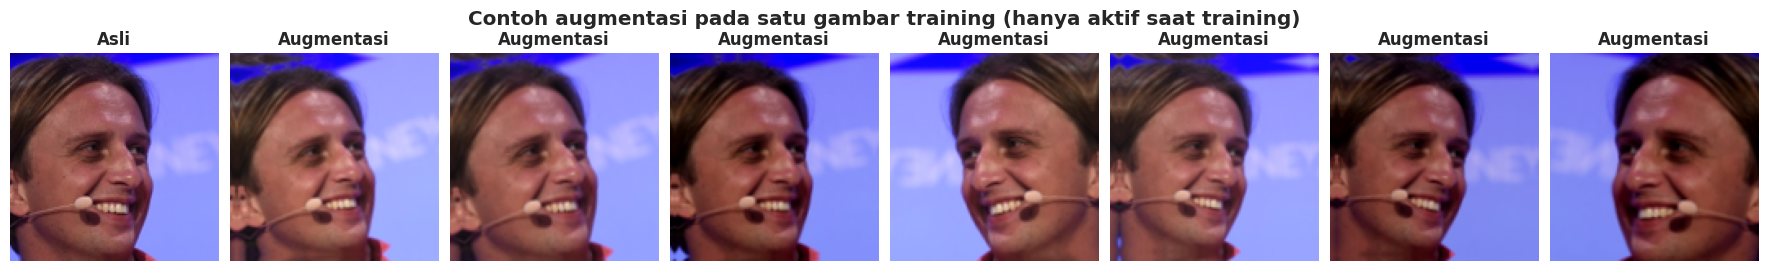

In [8]:
def load_resized_array(path):
    return np.asarray(Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype="float32")


def show_augmentation_examples(df, n_examples=7):
    """Tampilkan gambar asli dan beberapa hasil augmentasi acak dari gambar yang sama."""
    original = load_resized_array(df.iloc[0]["path"])
    augmenter = build_augmentation()
    fig, axes = plt.subplots(1, n_examples + 1, figsize=(2.2 * (n_examples + 1), 2.6), constrained_layout=True)
    axes[0].imshow(original.astype("uint8"))
    axes[0].set_title("Asli")
    for ax in axes[1:]:
        augmented = augmenter(original[None], training=True)[0].numpy()
        ax.imshow(np.clip(augmented, 0, 255).astype("uint8"))
        ax.set_title("Augmentasi")
    for ax in axes:
        ax.axis("off")
    fig.suptitle("Contoh augmentasi pada satu gambar training (hanya aktif saat training)", fontweight="bold")
    plt.show()


show_augmentation_examples(train_df)

In [9]:
preprocessing_log = pd.DataFrame([
    ("1", "Subset seimbang dari split resmi", f"train {len(train_df):,} | valid {len(val_df):,} | test {len(test_df):,} gambar (setelah pembersihan)",
     "Training tetap terjangkau di GPU gratis; kelas tetap 50:50; split resmi dipertahankan agar test tidak bocor"),
    ("2", "Hapus duplikat (hash MD5)", f"train {n_dup_train} | valid {n_dup_val} | test {n_dup_test} gambar dibuang",
     "Gambar identik di dua split membuat skor evaluasi terlalu optimis"),
    ("3", "Cek kebocoran antar-split", f"dibuang dari valid {n_leak_val} | dari train {n_leak_train} gambar",
     "Test dijaga utuh; valid dan train dibersihkan dari gambar yang sama dengan split lain"),
    ("4", "Resize", f"{native_w}x{native_h} -> {IMG_SIZE}x{IMG_SIZE} (bilinear + antialias)",
     "Ukuran input seragam dan komputasi lebih ringan; antialias mencegah aliasing saat gambar diperkecil"),
    ("5", "Normalisasi piksel", "skala 0-255 -> 0-1 lewat layer Rescaling di dalam model (ikut tersimpan untuk deployment)",
     "API cukup mengirim piksel 0-255, sehingga skala saat training dan deployment tidak bisa berbeda"),
    ("6", "Urutan data", "diacak penuh setiap epoch (tf.data shuffle, seed tetap)",
     "Batch tidak berisi satu kelas saja dan urutannya dapat direproduksi"),
    ("7", "Augmentasi (hanya training)", "flip horizontal, rotasi +/-3% putaran, zoom 10%, brightness 10%, contrast 10%",
     "Mengurangi overfitting; dibuat ringan supaya artefak khas generator tidak hilang"),
    ("8", "Penanganan imbalance", "tidak diperlukan: dataset seimbang 50:50",
     "Tidak ada kelas yang mendominasi"),
    ("9", "Face detection / cropping", "tidak diperlukan: wajah sudah ter-align pada dataset",
     "Dataset berisi potongan wajah yang sudah ter-align"),
], columns=["No", "Langkah", "Parameter dan hasil", "Alasan"])
display(preprocessing_log.style.hide(axis="index"))

No,Langkah,Parameter dan hasil,Alasan
1,Subset seimbang dari split resmi,"train 20,000 | valid 4,000 | test 10,000 gambar (setelah pembersihan)",Training tetap terjangkau di GPU gratis; kelas tetap 50:50; split resmi dipertahankan agar test tidak bocor
2,Hapus duplikat (hash MD5),train 0 | valid 0 | test 0 gambar dibuang,Gambar identik di dua split membuat skor evaluasi terlalu optimis
3,Cek kebocoran antar-split,dibuang dari valid 0 | dari train 0 gambar,Test dijaga utuh; valid dan train dibersihkan dari gambar yang sama dengan split lain
4,Resize,256x256 -> 128x128 (bilinear + antialias),Ukuran input seragam dan komputasi lebih ringan; antialias mencegah aliasing saat gambar diperkecil
5,Normalisasi piksel,skala 0-255 -> 0-1 lewat layer Rescaling di dalam model (ikut tersimpan untuk deployment),"API cukup mengirim piksel 0-255, sehingga skala saat training dan deployment tidak bisa berbeda"
6,Urutan data,"diacak penuh setiap epoch (tf.data shuffle, seed tetap)",Batch tidak berisi satu kelas saja dan urutannya dapat direproduksi
7,Augmentasi (hanya training),"flip horizontal, rotasi +/-3% putaran, zoom 10%, brightness 10%, contrast 10%",Mengurangi overfitting; dibuat ringan supaya artefak khas generator tidak hilang
8,Penanganan imbalance,tidak diperlukan: dataset seimbang 50:50,Tidak ada kelas yang mendominasi
9,Face detection / cropping,tidak diperlukan: wajah sudah ter-align pada dataset,Dataset berisi potongan wajah yang sudah ter-align


---
## 6. Exploratory Data Analysis (EDA)

Untuk data gambar, EDA dilakukan dengan mengekstrak **fitur ringkas per gambar** lalu membandingkannya antar kelas. Tujuannya sesuai guideline: memahami distribusi data, hubungan antar fitur, dan pola yang akan memandu keputusan modeling.

| Analisis | Pertanyaan yang dijawab |
|---|---|
| Distribusi kelas | Apakah data seimbang di semua split? |
| Contoh gambar | Apakah wajah palsu terlihat berbeda dengan mata telanjang? |
| Ukuran file, kecerahan, kontras, ketajaman, warna | Apakah ada perbedaan statistik sederhana antara real dan fake? |
| Gambar rata-rata | Apakah ada pola spasial yang berbeda? |
| Spektrum frekuensi (FFT) | Apakah generator meninggalkan jejak pada frekuensi tinggi? (dasar: paper 5 dan 6) |
| Uji statistik per fitur | Fitur sederhana mana yang paling memisahkan kelas, dan apakah ada risiko *shortcut learning*? |

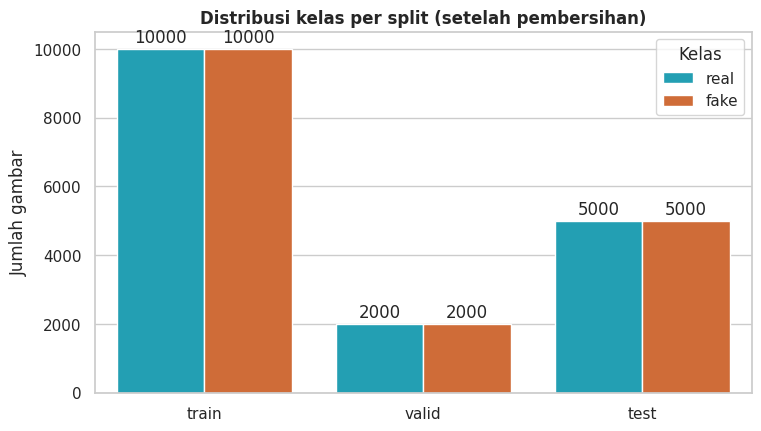

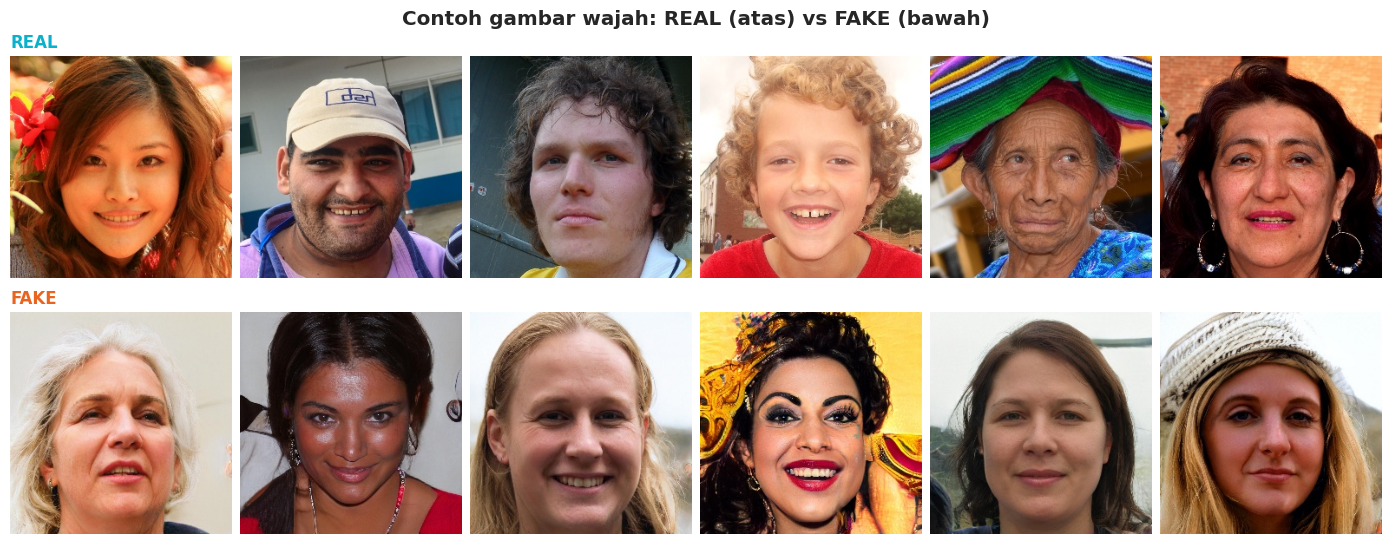

In [10]:
def plot_class_distribution(splits):
    """Bar chart jumlah gambar per kelas pada tiap split."""
    frame = pd.concat([df.assign(split=name) for name, df in splits.items()])
    fig, ax = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
    sns.countplot(data=frame, x="split", hue="label_str", order=list(splits), hue_order=CLASS_NAMES,
                  palette=PALETTE, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%d", padding=2)
    ax.set(title="Distribusi kelas per split (setelah pembersihan)", xlabel="", ylabel="Jumlah gambar")
    ax.legend(title="Kelas")
    plt.show()


def show_sample_grid(df, n_per_class=6):
    """Grid contoh gambar real (atas) vs fake (bawah)."""
    fig, axes = plt.subplots(len(CLASS_NAMES), n_per_class, figsize=(2.3 * n_per_class, 2.7 * len(CLASS_NAMES)),
                             constrained_layout=True)
    for row, class_name in enumerate(CLASS_NAMES):
        paths = df[df["label_str"] == class_name].sample(n_per_class, random_state=SEED)["path"]
        for col, path in enumerate(paths):
            axes[row, col].imshow(Image.open(path).convert("RGB"))
            axes[row, col].axis("off")
        axes[row, 0].set_title(class_name.upper(), loc="left", color=PALETTE[class_name], fontweight="bold")
    fig.suptitle("Contoh gambar wajah: REAL (atas) vs FAKE (bawah)", fontweight="bold")
    plt.show()


plot_class_distribution({"train": train_df, "valid": val_df, "test": test_df})
show_sample_grid(train_df)

In [11]:
GRAY_WEIGHTS = np.array([0.299, 0.587, 0.114])
THUMB_SIZE = 128


@lru_cache(maxsize=4)
def radius_grid(height, width):
    """Jarak (dibulatkan) tiap piksel ke pusat spektrum."""
    yy, xx = np.indices((height, width))
    return np.sqrt((yy - height // 2) ** 2 + (xx - width // 2) ** 2).astype(int)


@lru_cache(maxsize=4)
def hann_window(height, width):
    return np.outer(np.hanning(height), np.hanning(width))


def power_spectrum(gray):
    """Spektrum daya 2D terpusat beserta profil radialnya (rata-rata daya pada tiap jarak dari pusat)."""
    height, width = gray.shape
    windowed = (gray - gray.mean()) * hann_window(height, width)
    power = np.abs(np.fft.fftshift(np.fft.fft2(windowed))) ** 2
    radius = radius_grid(height, width)
    sums = np.bincount(radius.ravel(), weights=power.ravel())
    counts = np.bincount(radius.ravel())
    max_radius = min(height, width) // 2
    return power, (sums / np.maximum(counts, 1))[:max_radius]


def analyze_images(df):
    """Satu kali pass: statistik warna dan ketajaman, spektrum frekuensi, serta thumbnail tiap gambar."""
    rows, profiles, thumbs = [], [], []
    spectrum_sum, spectrum_count = {}, {}
    for path, label in tqdm(zip(df["path"], df["label"]), total=len(df), desc="Analisis gambar"):
        with Image.open(path) as image:
            image = image.convert("RGB")
            rgb = np.asarray(image, dtype=np.float64)
            thumbs.append(np.asarray(image.resize((THUMB_SIZE, THUMB_SIZE), Image.Resampling.BILINEAR)))
        gray = rgb @ GRAY_WEIGHTS
        power, profile = power_spectrum(gray)
        high_freq = radius_grid(*gray.shape) >= min(gray.shape) // 4      # >= 50% frekuensi Nyquist
        rows.append({
            "path": path, "label": label, "label_str": CLASS_NAMES[label],
            "file_kb": os.path.getsize(path) / 1024,
            "mean_r": rgb[..., 0].mean(), "mean_g": rgb[..., 1].mean(), "mean_b": rgb[..., 2].mean(),
            "brightness": gray.mean(), "contrast": gray.std(),
            "sharpness": ndimage.laplace(gray).var(),
            "hf_ratio": power[high_freq].sum() / power.sum(),
        })
        profiles.append(profile)
        spectrum_sum[label] = spectrum_sum.get(label, 0) + np.log10(power + 1e-8)
        spectrum_count[label] = spectrum_count.get(label, 0) + 1
    features = pd.DataFrame(rows)
    features["warmth"] = features["mean_r"] - features["mean_b"]
    return {"features": features, "profiles": np.array(profiles), "thumbs": np.stack(thumbs),
            "mean_spectrum": {k: spectrum_sum[k] / spectrum_count[k] for k in spectrum_sum}}


eda_sample = stratified_sample(train_df, EDA_N_PER_CLASS)
eda = analyze_images(eda_sample)
feat_df, profiles, thumbs, mean_spectrum = eda["features"], eda["profiles"], eda["thumbs"], eda["mean_spectrum"]
eda_labels = feat_df["label"].to_numpy()
display(feat_df.groupby("label_str")[["file_kb", "brightness", "contrast", "sharpness", "hf_ratio", "warmth"]]
        .agg(["mean", "std"]).round(4).T)

Analisis gambar:   0%|          | 0/1600 [00:00<?, ?it/s]

label_str             fake       real
file_kb    mean    28.0174    28.2737
           std      3.9939     3.7823
brightness mean   112.4571   113.7432
           std     27.3523    26.6037
contrast   mean    57.0524    58.2175
           std     11.0084    10.4658
sharpness  mean  1040.9914  1187.2138
           std    878.8438   777.9661
hf_ratio   mean     0.0152     0.0181
           std      0.0110     0.0136
warmth     mean    36.0196    35.2356
           std     21.5010    20.9238

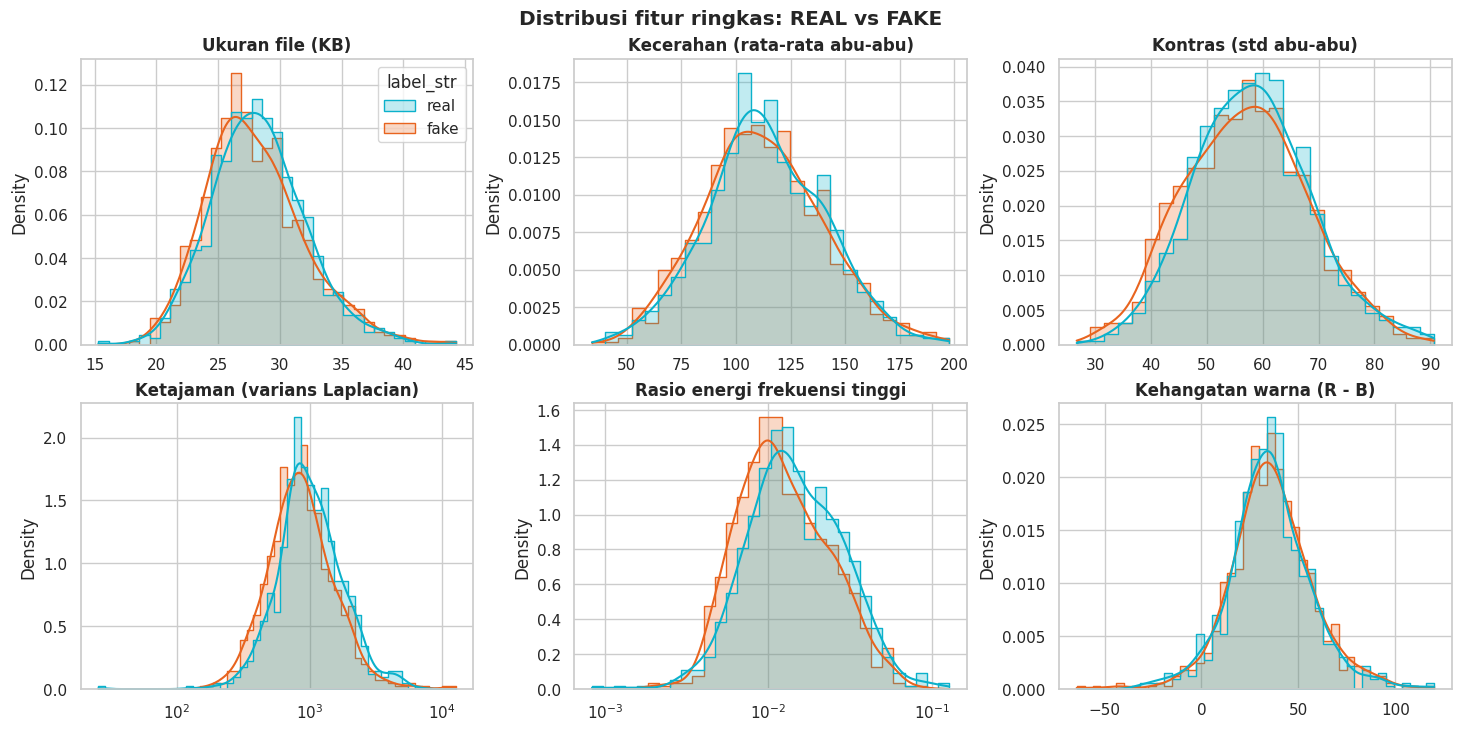

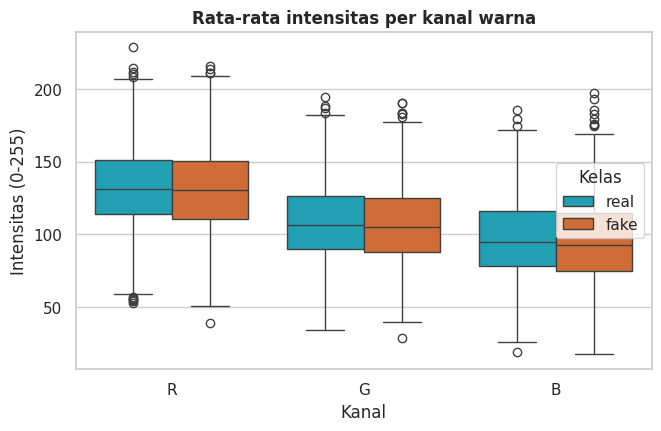

In [12]:
FEATURE_TITLES = {
    "file_kb": "Ukuran file (KB)", "brightness": "Kecerahan (rata-rata abu-abu)", "contrast": "Kontras (std abu-abu)",
    "sharpness": "Ketajaman (varians Laplacian)", "hf_ratio": "Rasio energi frekuensi tinggi",
    "warmth": "Kehangatan warna (R - B)",
}
LOG_SCALE_FEATURES = {"sharpness", "hf_ratio"}


def plot_feature_distributions(features):
    """Histogram + KDE per fitur, dipisah menurut kelas."""
    fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.2), constrained_layout=True)
    for ax, (feature, title) in zip(axes.ravel(), FEATURE_TITLES.items()):
        sns.histplot(data=features, x=feature, hue="label_str", hue_order=CLASS_NAMES, palette=PALETTE, kde=True,
                     stat="density", common_norm=False, element="step", log_scale=feature in LOG_SCALE_FEATURES, ax=ax)
        ax.set(title=title, xlabel="")
        if ax.get_legend() is not None and feature != "file_kb":
            ax.get_legend().remove()
    fig.suptitle("Distribusi fitur ringkas: REAL vs FAKE", fontweight="bold")
    plt.show()


def plot_color_channels(features):
    """Boxplot rata-rata intensitas kanal R, G, B per kelas."""
    long = features.melt(id_vars="label_str", value_vars=["mean_r", "mean_g", "mean_b"],
                         var_name="kanal", value_name="intensitas")
    long["kanal"] = long["kanal"].str[-1].str.upper()
    fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
    sns.boxplot(data=long, x="kanal", y="intensitas", hue="label_str", hue_order=CLASS_NAMES, palette=PALETTE, ax=ax)
    ax.set(title="Rata-rata intensitas per kanal warna", xlabel="Kanal", ylabel="Intensitas (0-255)")
    ax.legend(title="Kelas")
    plt.show()


plot_feature_distributions(feat_df)
plot_color_channels(feat_df)

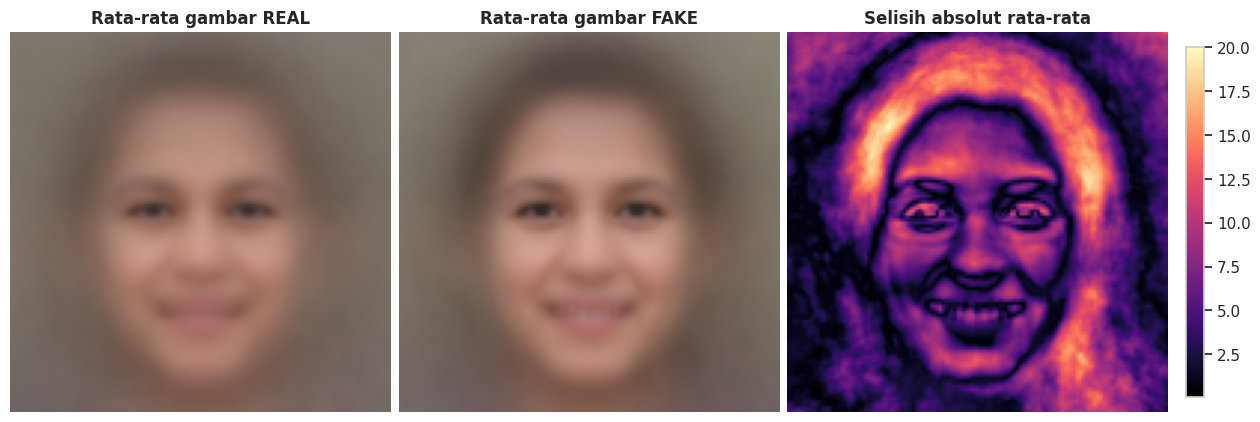

In [13]:
def plot_mean_images(thumbnails, labels):
    """Gambar rata-rata tiap kelas dan selisih absolutnya."""
    mean_real = thumbnails[labels == CLASS_TO_IDX["real"]].mean(axis=0)
    mean_fake = thumbnails[labels == CLASS_TO_IDX["fake"]].mean(axis=0)
    difference = np.abs(mean_real - mean_fake).mean(axis=-1)
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), constrained_layout=True)
    axes[0].imshow(mean_real.astype("uint8"))
    axes[0].set_title("Rata-rata gambar REAL")
    axes[1].imshow(mean_fake.astype("uint8"))
    axes[1].set_title("Rata-rata gambar FAKE")
    image = axes[2].imshow(difference, cmap="magma")
    axes[2].set_title("Selisih absolut rata-rata")
    fig.colorbar(image, ax=axes[2], fraction=0.046)
    for ax in axes:
        ax.axis("off")
    plt.show()


plot_mean_images(thumbs, eda_labels)

**Cara membaca analisis frekuensi (sel berikut):** setiap gambar diubah ke domain frekuensi dengan FFT 2D. Pusat spektrum = frekuensi rendah (bentuk umum wajah), tepi = frekuensi tinggi (detail halus dan noise). Pada gambar asli, energi biasanya menurun mulus ke arah frekuensi tinggi. Paper 5 dan 6 melaporkan bahwa proses *upsampling* pada generator GAN meninggalkan pola yang menyimpang pada frekuensi tinggi, sehingga profil radial kedua kelas bisa berbeda.

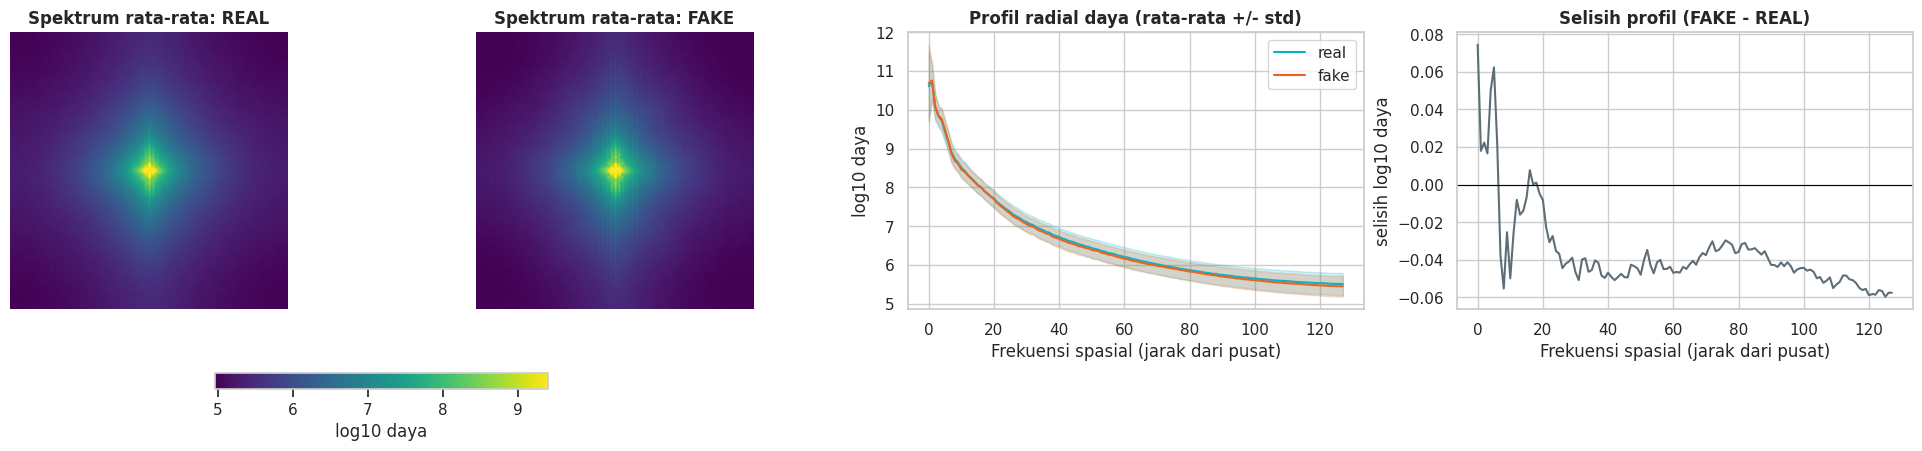

In [14]:
def plot_frequency_analysis(spectra, radial_profiles, labels):
    """Spektrum 2D rata-rata, profil radial, dan selisih profil antar kelas."""
    log_profiles = {name: np.log10(radial_profiles[labels == idx] + 1e-8) for name, idx in CLASS_TO_IDX.items()}
    all_values = np.concatenate([spectrum.ravel() for spectrum in spectra.values()])
    vmin, vmax = np.percentile(all_values, [1, 99.9])      # abaikan puncak DC agar struktur lain terlihat
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.4), constrained_layout=True)

    for ax, name in zip(axes[:2], CLASS_NAMES):
        image = ax.imshow(spectra[CLASS_TO_IDX[name]], cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_title(f"Spektrum rata-rata: {name.upper()}")
        ax.axis("off")
    fig.colorbar(image, ax=axes[:2], location="bottom", fraction=0.06, pad=0.04, label="log10 daya")

    radius = np.arange(log_profiles["real"].shape[1])
    for name in CLASS_NAMES:
        mean, std = log_profiles[name].mean(axis=0), log_profiles[name].std(axis=0)
        axes[2].plot(radius, mean, color=PALETTE[name], label=name)
        axes[2].fill_between(radius, mean - std, mean + std, color=PALETTE[name], alpha=0.2)
    axes[2].set(title="Profil radial daya (rata-rata +/- std)", xlabel="Frekuensi spasial (jarak dari pusat)",
                ylabel="log10 daya")
    axes[2].legend()

    gap = log_profiles["fake"].mean(axis=0) - log_profiles["real"].mean(axis=0)
    axes[3].plot(radius, gap, color="#5E6E77")
    axes[3].axhline(0, color="black", linewidth=0.8)
    axes[3].set(title="Selisih profil (FAKE - REAL)", xlabel="Frekuensi spasial (jarak dari pusat)", ylabel="selisih log10 daya")
    plt.show()
    return gap


spectrum_gap = plot_frequency_analysis(mean_spectrum, profiles, eda_labels)

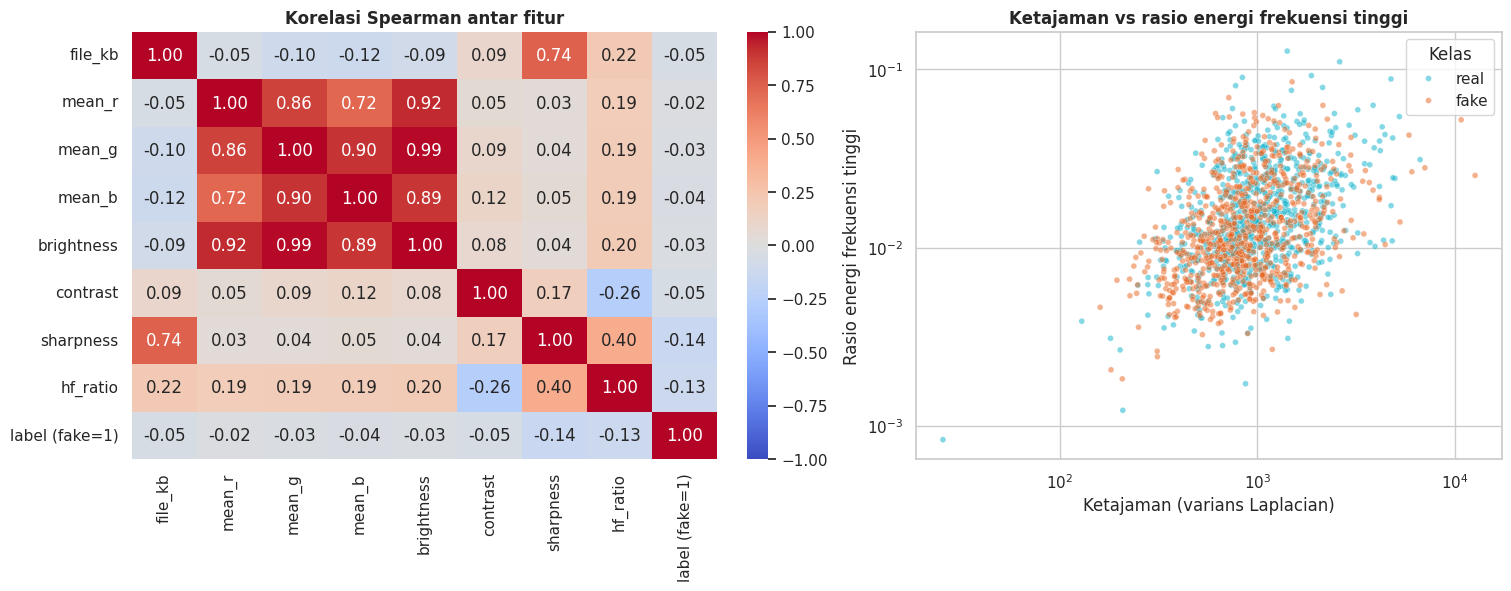

In [15]:
def plot_feature_relationships(features):
    """Heatmap korelasi Spearman dan scatter plot ketajaman vs energi frekuensi tinggi."""
    columns = ["file_kb", "mean_r", "mean_g", "mean_b", "brightness", "contrast", "sharpness", "hf_ratio"]
    numeric = features[columns].copy()
    numeric["label (fake=1)"] = features["label"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), constrained_layout=True)
    sns.heatmap(numeric.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, ax=axes[0])
    axes[0].set_title("Korelasi Spearman antar fitur")
    sns.scatterplot(data=features, x="sharpness", y="hf_ratio", hue="label_str", hue_order=CLASS_NAMES,
                    palette=PALETTE, alpha=0.5, s=18, ax=axes[1])
    axes[1].set(xscale="log", yscale="log", title="Ketajaman vs rasio energi frekuensi tinggi",
                xlabel="Ketajaman (varians Laplacian)", ylabel="Rasio energi frekuensi tinggi")
    axes[1].legend(title="Kelas")
    plt.show()


plot_feature_relationships(feat_df)

In [16]:
def univariate_separability(features, columns):
    """Uji Mann-Whitney per fitur. AUC univariat = peluang fitur tunggal memisahkan real vs fake (0.5 = acak)."""
    real = features[features["label_str"] == "real"]
    fake = features[features["label_str"] == "fake"]
    rows = []
    for column in columns:
        u_stat, p_value = stats.mannwhitneyu(real[column], fake[column], alternative="two-sided")
        auc = u_stat / (len(real) * len(fake))
        rows.append({"fitur": column, "median_real": real[column].median(), "median_fake": fake[column].median(),
                     "lebih_tinggi_pada": "real" if auc > 0.5 else "fake", "p_value": p_value,
                     "AUC_univariat": max(auc, 1 - auc)})
    return pd.DataFrame(rows).sort_values("AUC_univariat", ascending=False).reset_index(drop=True)


separability = univariate_separability(feat_df, list(FEATURE_TITLES))
display(separability.style.format({"median_real": "{:.4g}", "median_fake": "{:.4g}", "p_value": "{:.2e}",
                                   "AUC_univariat": "{:.3f}"}).hide(axis="index"))

fitur,median_real,median_fake,lebih_tinggi_pada,p_value,AUC_univariat
sharpness,966.6,846.3,real,7.75e-09,0.583
hf_ratio,0.01382,0.01146,real,2.21e-07,0.575
file_kb,28.05,27.53,real,4.16e-02,0.529
contrast,57.87,57.1,real,4.92e-02,0.528
brightness,112.5,110.9,real,2.49e-01,0.517
warmth,34.67,35.22,fake,3.87e-01,0.512


In [17]:
def summarize_eda(features, separability_table, high_freq_gap):
    """Ringkasan EDA yang dihitung otomatis dari data (bukan teks tetap)."""
    counts = features["label_str"].value_counts()
    top = separability_table.iloc[0]
    strong = separability_table[separability_table["AUC_univariat"] >= 0.80]
    tail = high_freq_gap[len(high_freq_gap) * 3 // 4:].mean()
    lines = [
        f"- **Keseimbangan kelas:** sampel EDA terdiri dari {counts.get('real', 0):,} real dan {counts.get('fake', 0):,} fake.",
        f"- **Fitur sederhana paling membedakan:** `{top['fitur']}` dengan AUC univariat {top['AUC_univariat']:.3f} "
        f"(nilainya lebih tinggi pada kelas {top['lebih_tinggi_pada']}).",
        f"- **Energi frekuensi tinggi:** pada seperempat frekuensi tertinggi, selisih daya FAKE - REAL = {tail:+.3f} (skala log10), "
        f"artinya gambar fake memiliki energi frekuensi tinggi yang {'lebih besar' if tail > 0 else 'lebih kecil'} daripada real.",
    ]
    if len(strong):
        names = ", ".join(f"`{name}`" for name in strong["fitur"])
        lines.append(f"- **Peringatan shortcut learning:** fitur {names} sudah memisahkan kelas dengan AUC univariat >= 0.80. "
                     "Model berisiko belajar dari artefak non-wajah (misalnya kompresi file) dan bukan dari struktur wajah. "
                     "Karena itu Bagian 8 memverifikasi dengan Grad-CAM dan uji ketahanan.")
    else:
        lines.append("- **Shortcut learning:** tidak ada fitur sederhana dengan AUC univariat >= 0.80, jadi pemisahan kelas "
                     "membutuhkan pola kompleks yang dipelajari CNN.")
    display(Markdown("### Ringkasan EDA\n" + "\n".join(lines)))


summarize_eda(feat_df, separability, spectrum_gap)

### Ringkasan EDA
- **Keseimbangan kelas:** sampel EDA terdiri dari 800 real dan 800 fake.
- **Fitur sederhana paling membedakan:** `sharpness` dengan AUC univariat 0.583 (nilainya lebih tinggi pada kelas real).
- **Energi frekuensi tinggi:** pada seperempat frekuensi tertinggi, selisih daya FAKE - REAL = -0.052 (skala log10), artinya gambar fake memiliki energi frekuensi tinggi yang lebih kecil daripada real.
- **Shortcut learning:** tidak ada fitur sederhana dengan AUC univariat >= 0.80, jadi pemisahan kelas membutuhkan pola kompleks yang dipelajari CNN.

**Implikasi EDA untuk modeling**
- Data seimbang, jadi tidak perlu *class weight* maupun oversampling.
- Perbedaan statistik sederhana (jika ada) menjadi alasan untuk **tidak hanya mengandalkan akurasi**: model perlu divalidasi dengan Grad-CAM dan uji ketahanan terhadap kompresi, blur, dan perubahan resolusi.
- Jejak pada domain frekuensi mendukung pemilihan **CNN** sebagai pengekstrak fitur lokal, lalu **MHSA** untuk menangkap hubungan antar-wilayah wajah (pendekatan paper 1).

---
## 7. Model Selection dan Training

### 7.1 Arsitektur yang Dipilih
Dua model dibandingkan (*ablation*) dengan backbone konvolusi yang **identik**. Perbedaannya hanya ada pada ada tidaknya blok attention:

```
Input (IMG_SIZE x IMG_SIZE x 3, piksel 0-255)
  -> Augmentasi (hanya saat training) -> Rescaling 1/255
  -> [Conv-BN-ReLU x2 -> MaxPool -> Dropout] x N blok          (filter b, 2b, 4b, 8b)
  -> CNN + MHSA : Reshape jadi deretan token -> Multi-Head Self-Attention + Residual + LayerNorm -> GlobalAvgPool1D
     CNN baseline: GlobalAvgPool2D langsung
  -> Dense(128, "embedding") -> Dropout -> Dense(1, sigmoid) = P(fake)
```

**Alasan pemilihan**
- CNN mengekstrak pola lokal (tekstur kulit, tepi rambut, artefak halus), sedangkan MHSA menghubungkan wilayah wajah yang berjauhan (mata, mulut, latar). Kombinasi ini yang dilaporkan efektif pada paper 1 dan 3.
- Dilatih dari nol (bukan pretrained ImageNet) supaya model bisa mempelajari artefak tingkat rendah khas generator, dan ukurannya kecil sehingga tuning terjangkau.
- Layer `Rescaling` dan augmentasi berada **di dalam model**, jadi saat deployment cukup mengirim gambar yang sudah di-resize dengan skala 0-255.
- Transfer learning (misalnya EfficientNet pada paper 2 dan 4) dicatat sebagai pengembangan lanjutan pada Bagian 10.

In [18]:
MODEL_COLORS = ["#5E6E77", "#0891A8"]      # abu-abu = baseline, teal = CNN + MHSA


def conv_block(x, filters, dropout, block_id):
    """Dua Conv-BN-ReLU, lalu MaxPooling dan Dropout."""
    for step in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"block{block_id}_conv{step}")(x)
        x = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"block{block_id}_bn{step}")(x)
        x = layers.Activation("relu", name=f"block{block_id}_relu{step}")(x)
    x = layers.MaxPooling2D(name=f"block{block_id}_pool")(x)
    return layers.Dropout(dropout, name=f"block{block_id}_drop")(x)


def attention_block(x, num_heads, dropout):
    """Ubah feature map menjadi deretan token, lalu terapkan MHSA + residual + LayerNorm."""
    height, width, channels = x.shape[1], x.shape[2], x.shape[3]
    tokens = layers.Reshape((height * width, channels), name="tokens")(x)
    attended = layers.MultiHeadAttention(num_heads=num_heads, key_dim=channels // num_heads,
                                         dropout=dropout, name="mhsa")(tokens, tokens)
    tokens = layers.Add(name="mhsa_residual")([tokens, attended])
    tokens = layers.LayerNormalization(epsilon=1e-6, name="mhsa_norm")(tokens)
    return layers.GlobalAveragePooling1D(name="gap")(tokens)


def build_model(use_attention, base_filters=32, num_blocks=4, num_heads=4, dropout=0.3, name=None):
    """CNN baseline (use_attention=False) atau CNN + MHSA (use_attention=True)."""
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)
    for block_id in range(1, num_blocks + 1):
        x = conv_block(x, base_filters * 2 ** (block_id - 1), dropout * 0.5, block_id)
    if use_attention:
        x = attention_block(x, num_heads, dropout * 0.5)
    else:
        x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, activation="relu", name="embedding")(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="p_fake")(x)
    return keras.Model(inputs, outputs, name=name or ("cnn_mhsa" if use_attention else "cnn_baseline"))


demo_mhsa = build_model(use_attention=True)
demo_base = build_model(use_attention=False)
print(f"Parameter (konfigurasi default) -> CNN baseline: {demo_base.count_params():,} | CNN + MHSA: {demo_mhsa.count_params():,}")
demo_mhsa.summary(line_length=100)
del demo_mhsa, demo_base

Parameter (konfigurasi default) -> CNN baseline: 1,208,161 | CNN + MHSA: 1,471,841


Model: "cnn_mhsa"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)          │ (None, 128, 128, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ augmentation (Sequential)   │ (None, 128, 128, 3)     │              0 │ image[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ rescale (Rescaling)         │ (None, 128, 128, 3)     │              0 │ augmentation[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv1 (Conv2D)       │ (None, 128, 128, 32)    │            864 │ rescale[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_bn1                  │ (None, 128, 128, 32)    │            128 │ block1_conv1[0][0]      │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_relu1 (Activation)   │ (None, 128, 128, 32)    │              0 │ block1_bn1[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv2 (Conv2D)       │ (None, 128, 128, 32)    │          9,216 │ block1_relu1[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_bn2                  │ (None, 128, 128, 32)    │            128 │ block1_conv2[0][0]      │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_relu2 (Activation)   │ (None, 128, 128, 32)    │              0 │ block1_bn2[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_pool (MaxPooling2D)  │ (None, 64, 64, 32)      │              0 │ block1_relu2[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_drop (Dropout)       │ (None, 64, 64, 32)      │              0 │ block1_pool[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_conv1 (Conv2D)       │ (None, 64, 64, 64)      │         18,432 │ block1_drop[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_bn1                  │ (None, 64, 64, 64)      │            256 │ block2_conv1[0][0]      │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_relu1 (Activation)   │ (None, 64, 64, 64)      │              0 │ block2_bn1[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_conv2 (Conv2D)       │ (None, 64, 64, 64)      │         36,864 │ block2_relu1[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_bn2                  │ (None, 64, 64, 64)      │            256 │ block2_conv2[0][0]      │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_relu2 (Activation)   │ (None, 64, 64, 64)      │    

 Total params: 1,471,841 (5.61 MB)

 Trainable params: 1,469,921 (5.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

### 7.2 Diagnosa Run Awal dan Keputusan Desain Training

Pada run awal (15 epoch, learning rate 1e-3 yang diturunkan otomatis oleh `ReduceLROnPlateau`), kurva **train** mulus tetapi kurva **validasi** (loss, accuracy, recall, precision) naik-turun dari epoch ke epoch. Penyebabnya dicari dari log training run itu **sebelum** hyperparameter diubah.

**Bukti dari log run awal**

| Pengamatan pada run awal | CNN baseline | CNN + MHSA |
|---|---|---|
| Fraksi gambar validasi yang diprediksi *fake* pada threshold 0,5 (idealnya sekitar 0,50) | 0,106 – 0,939 | 0,198 – 0,650 |
| Fraksi yang sama pada data train (mode training, rata-rata epoch) | 0,475 – 0,514 | 0,480 – 0,504 |
| Epoch dengan fraksi validasi di luar 0,35 – 0,65 | 8 dari 15 | 2 dari 15 |
| Gerak naik-turun berlebih per epoch: val accuracy | 0,0241 | 0,0171 |
| Gerak naik-turun berlebih per epoch: val loss | 0,0406 | 0,0220 |
| Gerak naik-turun berlebih per epoch: val AUC | 0,0011 | 0,0033 |
| Epoch tempat `ReduceLROnPlateau` menurunkan learning rate | 7 dan 9 | 4 dan 10 |
| Accuracy epoch terakhir: train / validasi | 0,8080 / 0,7945 | 0,8074 / 0,7977 |

*Gerak naik-turun berlebih* = total |perubahan| antar-epoch dikurangi |nilai akhir − nilai awal|, dibagi (jumlah epoch − 1). Kurva yang naik mulus bernilai 0.

**Apa yang ditunjukkan bukti ini**
1. **Yang bergejolak adalah titik keputusan, bukan kemampuan memisahkan kelas.** Val AUC (berbasis peringkat) hampir mulus, sedangkan fraksi gambar validasi yang diprediksi *fake* berayun dari 11% sampai 94% padahal separuhnya memang fake. Pada data train (mode training, dirata-rata sepanjang epoch) fraksi itu stabil di sekitar 50%. Model makin pandai mengurutkan gambar, tetapi titik potong 0,5 bergeser dari epoch ke epoch saat inferensi.
2. **Dugaan penyebab: statistik BatchNorm saat inferensi tidak mengikuti bobot cukup cepat.** Metrik train pada log Keras dihitung di mode training (BatchNorm memakai statistik batch; dropout dan augmentasi aktif) lalu dirata-rata sepanjang epoch, sedangkan metrik validasi adalah snapshot akhir epoch di mode inferensi, yang memakai moving average BatchNorm (momentum bawaan Keras 0,99, kira-kira rata-rata 100 langkah terakhir). Pada learning rate tinggi bobot berubah lebih cepat daripada moving average-nya, dan keluaran model masih jauh dari ekstrem (val loss sekitar 0,4), sehingga pergeseran kecil pada logit sudah membalik banyak prediksi di threshold 0,5. Penjelasan alternatif: bobot berayun dari langkah ke langkah pada learning rate tinggi, dan rata-rata epoch pada metrik train menyembunyikan ayunan itu. Log tidak bisa memisahkan keduanya dan tidak ada eksperimen terpisah pada model run awal, jadi ini dugaan; perubahan di bawah meredam kedua mekanisme, dan Bagian 7.5 mengukur hasilnya.
3. **Jadwal learning rate ditentukan oleh sinyal yang sendiri bergejolak.** `ReduceLROnPlateau` memantau `val_loss`, sehingga learning rate turun di epoch yang berbeda untuk dua model. Pada ablation, baseline dan CNN + MHSA akhirnya dilatih dengan jadwal learning rate berbeda, padahal perbandingan yang adil menuntut jadwal yang sama.
4. **Tuning tidak bisa membedakan konfigurasi.** Tiap trial hanya 3 epoch (282 – 564 langkah) dan semua val AUC berada di 0,51 – 0,60, nyaris tebakan acak. Learning rate dan batch size bercampur (learning rate 1e-4 selalu berpasangan dengan batch 64, learning rate 1e-3 dengan batch 32, dan 5e-4 tidak pernah terambil), sehingga peringkat tidak bisa dikaitkan ke salah satunya. Learning rate terpilih adalah yang terbesar di rentang dan dropout terpilih yang terkecil, sehingga rentang pencarian kemungkinan belum mengapit nilai optimum (dengan skor sedekat tebakan acak, ini pun baru dugaan).
5. **Tidak ada tanda overfitting.** Accuracy train 0,81 dan validasi 0,79 – 0,80 di epoch terakhir, metrik train masih naik pelan sampai epoch 15, dan early stopping tidak pernah terpicu (training berhenti karena epoch habis). Yang terbatas adalah kemampuan belajar, bukan generalisasi.

**Keputusan desain**

| Masalah | Perubahan | Alasan |
|---|---|---|
| Titik keputusan bergeser antar-epoch | `BatchNormalization(momentum=0.9)` | Moving average mengikuti bobot dalam kira-kira 10 langkah, bukan 100 |
| Learning rate dipotong oleh sinyal yang bergejolak, berbeda antar model | Warm-up 1 epoch lalu cosine decay ke 1% dari learning rate puncak; `ReduceLROnPlateau` dihapus | Jadwal deterministik dan identik untuk kedua model; learning rate kecil di akhir membuat bobot dan statistik BatchNorm menetap |
| Tuning 3 epoch tidak informatif dan learning rate bercampur dengan batch size | Dua tahap: grid learning rate × batch size, lalu random search arsitektur dan dropout. Tiap trial 5 epoch dengan jadwal yang sama; skor = val AUC epoch terakhir | Efek learning rate dan batch size terpisah; skor diukur saat learning rate sudah turun |
| Rentang pencarian mungkin tidak mengapit optimum | Learning rate 3e-4 – 3e-3, dropout 0 – 0,3 | Nilai terbaik sebelumnya berada di tepi rentang; rentang baru memberi ruang ke kedua arah |
| Model belum cukup belajar | 15 → 20 epoch; `EarlyStopping` (patience 8) hanya sebagai pengaman | Training sebelumnya berhenti karena epoch habis, bukan karena konvergen |
| Ablation bisa terdistorsi pergeseran titik keputusan | Tambahan selisih AUC berpasangan dan McNemar pada threshold masing-masing model (Bagian 8) | Perbandingan tidak bergantung pada threshold 0,5 |

Perubahan ini disusun dari diagnosa log. Dampaknya diukur lewat uji stabilitas di Bagian 7.5, yang menghitung metrik yang sama dari run ini dan membandingkannya dengan tabel di atas.

In [19]:
def make_lr_schedule(peak_lr, steps_per_epoch, epochs):
    """Warm-up linear lalu cosine decay. Jadwal ini deterministik (tidak bergantung pada metrik validasi),
    sehingga baseline dan CNN + MHSA pada ablation memakai learning rate yang persis sama di setiap langkah."""
    total_steps = max(2, steps_per_epoch * epochs)
    warmup_steps = min(max(1, round(WARMUP_EPOCHS * steps_per_epoch)), total_steps - 1)
    return keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=peak_lr / 10, decay_steps=total_steps - warmup_steps, alpha=LR_FINAL_RATIO,
        warmup_target=peak_lr, warmup_steps=warmup_steps)


def compile_model(model, learning_rate):
    """learning_rate boleh berupa angka tetap atau jadwal (lihat make_lr_schedule)."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")],
        jit_compile=False,
    )
    return model


def make_callbacks(checkpoint_path, patience=EARLY_STOP_PATIENCE):
    """EarlyStopping hanya pengaman. Learning rate sengaja TIDAK diatur oleh callback (lihat Bagian 7.2)."""
    return [
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(str(checkpoint_path), monitor="val_auc", mode="max", save_best_only=True),
    ]

### 7.3 Hyperparameter Tuning (Dua Tahap)
Guideline meminta eksperimen **learning rate, jumlah layer, dan ukuran batch**. Protokol tuning dirancang ulang berdasarkan diagnosa di Bagian 7.2:

1. **Tahap 1, grid learning rate × batch size** dengan arsitektur tetap. Dua hyperparameter yang paling memengaruhi stabilitas training ini diuji bersilang penuh, sehingga efek keduanya tidak tercampur.
2. **Tahap 2, random search arsitektur dan regularisasi** (lebar jaringan, jumlah blok konvolusi atau "jumlah layer", jumlah attention head, dropout) pada learning rate dan batch size terbaik dari tahap 1.

Aturan yang sama untuk semua trial:
- Tiap trial memakai jadwal learning rate yang sama dengan training final (warm-up lalu cosine decay) yang dipadatkan ke `TUNE_EPOCHS` epoch. **Skor = val AUC pada epoch terakhir**, saat learning rate sudah turun, bukan epoch terbaik dari beberapa epoch awal.
- Tuning dilakukan pada **subset kecil** agar murah, jadi hasilnya peringkat relatif antar konfigurasi, bukan perkiraan performa akhir. Selisih val AUC di bawah sekitar 0,01 masih dalam rentang noise (galat baku AUC pada 2.000 gambar validasi sekitar 0,01, ditambah variasi seed).
- Pemilihan memakai **val AUC** pada data **validasi**. Data **test tidak dipakai** pada tahap ini supaya evaluasi akhir tetap bersih.
- Rentang pencarian diperluas ke arah yang sebelumnya terpilih di tepi (learning rate sampai 3e-3, dropout sampai 0). Sel hasil tuning memberi peringatan bila nilai terbaik masih berada di tepi rentang.
- Jumlah trial tahap 2 dikendalikan `N_TRIALS`. Naikkan nilainya bila waktu dan GPU memungkinkan.

In [20]:
# Tahap 1: grid learning rate x batch size dengan arsitektur tetap (efek keduanya tidak boleh bercampur)
# Tahap 2: random search arsitektur dan dropout pada learning rate dan batch size terbaik tahap 1
STAGE1_SPACE = {"learning_rate": STAGE1_LRS, "batch_size": STAGE1_BATCH_SIZES}
STAGE1_ARCH = {"base_filters": 32, "num_blocks": 4, "num_heads": 4, "dropout": 0.2}
STAGE2_SPACE = {
    "base_filters": [16, 32],
    "num_blocks": [3, 4],            # jumlah blok konvolusi ("jumlah layer")
    "num_heads": [2, 4, 8],
    "dropout": [0.0, 0.1, 0.2, 0.3],
}
SEARCH_SPACE = {**STAGE1_SPACE, **STAGE2_SPACE}      # seluruh hyperparameter yang dituning


def sample_configs(space, n_trials, seed=SEED):
    """Ambil n kombinasi hyperparameter unik secara acak."""
    combos = list(itertools.product(*space.values()))
    chosen = random.Random(seed).sample(combos, k=min(n_trials, len(combos)))
    return [dict(zip(space.keys(), combo)) for combo in chosen]


def final_value(history, key):
    """Nilai epoch terakhir (0.0 bila training dihentikan sebelum validasi pertama, mis. karena NaN)."""
    values = history.get(key, [])
    return float(values[-1]) if len(values) and np.isfinite(values[-1]) else 0.0


def run_trial(config, train_subset, val_subset, epochs):
    """Latih CNN + MHSA dengan satu konfigurasi memakai jadwal learning rate yang sama seperti training final."""
    keras.backend.clear_session()
    gc.collect()
    model = build_model(True, config["base_filters"], config["num_blocks"], config["num_heads"], config["dropout"])
    steps_per_epoch = int(np.ceil(len(train_subset) / config["batch_size"]))
    compile_model(model, make_lr_schedule(config["learning_rate"], steps_per_epoch, epochs))
    train_ds = make_dataset(train_subset, config["batch_size"], training=True)
    val_ds = make_dataset(val_subset, config["batch_size"], training=False)
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                        callbacks=[keras.callbacks.TerminateOnNaN()]).history
    # Skor = metrik epoch TERAKHIR (learning rate sudah turun), bukan epoch terbaik
    return {**config, "val_auc": final_value(history, "val_auc"), "val_accuracy": final_value(history, "val_accuracy"),
            "val_loss": final_value(history, "val_loss"), "minutes": (time.time() - start) / 60}


tune_train = stratified_sample(train_df, N_TUNE_TRAIN_PER_CLASS)
tune_val = stratified_sample(val_df, N_TUNE_VAL_PER_CLASS)
trial_results = []


def run_stage(stage_name, configs):
    for number, config in enumerate(configs, start=1):
        keras.utils.set_random_seed(SEED)
        result = {**run_trial(config, tune_train, tune_val, TUNE_EPOCHS), "stage": stage_name}
        trial_results.append(result)
        print(f"[{stage_name}] {number}/{len(configs)} | val_auc={result['val_auc']:.4f} | {result['minutes']:.1f} menit | {config}")


stage1_configs = [{**dict(zip(STAGE1_SPACE, combo)), **STAGE1_ARCH} for combo in itertools.product(*STAGE1_SPACE.values())]
run_stage("tahap 1", stage1_configs)
best_stage1 = max(trial_results, key=lambda result: result["val_auc"])
print(f"Terbaik tahap 1: learning_rate={best_stage1['learning_rate']:.0e}, batch_size={best_stage1['batch_size']}")

# Tahap 2: konfigurasi arsitektur acak (tanpa mengulang arsitektur default yang sudah diuji di tahap 1)
arch_configs = [config for config in sample_configs(STAGE2_SPACE, N_TRIALS + 1) if config != STAGE1_ARCH][:N_TRIALS]
stage2_configs = [{**config, "learning_rate": best_stage1["learning_rate"], "batch_size": best_stage1["batch_size"]}
                  for config in arch_configs]
run_stage("tahap 2", stage2_configs)

[tahap 1] 1/6 | val_auc=0.7589 | 2.8 menit | {'learning_rate': 0.0003, 'batch_size': 32, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.2}
[tahap 1] 2/6 | val_auc=0.7543 | 3.1 menit | {'learning_rate': 0.0003, 'batch_size': 64, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.2}
[tahap 1] 3/6 | val_auc=0.7142 | 2.5 menit | {'learning_rate': 0.001, 'batch_size': 32, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.2}
[tahap 1] 4/6 | val_auc=0.7208 | 2.9 menit | {'learning_rate': 0.001, 'batch_size': 64, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.2}
[tahap 1] 5/6 | val_auc=0.5335 | 2.4 menit | {'learning_rate': 0.003, 'batch_size': 32, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.2}
[tahap 1] 6/6 | val_auc=0.5563 | 2.7 menit | {'learning_rate': 0.003, 'batch_size': 64, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.2}
Terbaik tahap 1: learning_rate=3e-04, batch_size=32
[tah

stage,learning_rate,batch_size,base_filters,num_blocks,num_heads,dropout,val_auc,val_accuracy,val_loss,minutes
tahap 2,3e-04,32,32,4,4,0.0,0.8293,0.7475,0.5100,2.7
tahap 1,3e-04,32,32,4,4,0.2,0.7589,0.6790,0.5899,2.8
tahap 1,3e-04,64,32,4,4,0.2,0.7543,0.6730,0.6176,3.1
tahap 2,3e-04,32,16,3,2,0.1,0.7410,0.6820,0.6027,1.5
tahap 2,3e-04,32,32,4,8,0.3,0.7396,0.6680,0.6116,2.4
tahap 1,1e-03,64,32,4,4,0.2,0.7208,0.6570,0.6206,2.9
tahap 1,1e-03,32,32,4,4,0.2,0.7142,0.6485,0.6246,2.5
tahap 2,3e-04,32,16,3,4,0.3,0.6820,0.6315,0.6406,1.6
tahap 1,3e-03,64,32,4,4,0.2,0.5563,0.5470,0.6882,2.7
tahap 1,3e-03,32,32,4,4,0.2,0.5335,0.5270,0.6927,2.4


Konfigurasi terbaik: {'learning_rate': 0.0003, 'batch_size': 32, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.0}
Perhatian: nilai terbaik berada di tepi rentang pencarian untuk ['learning_rate', 'dropout'] -> pertimbangkan memperluas rentangnya.


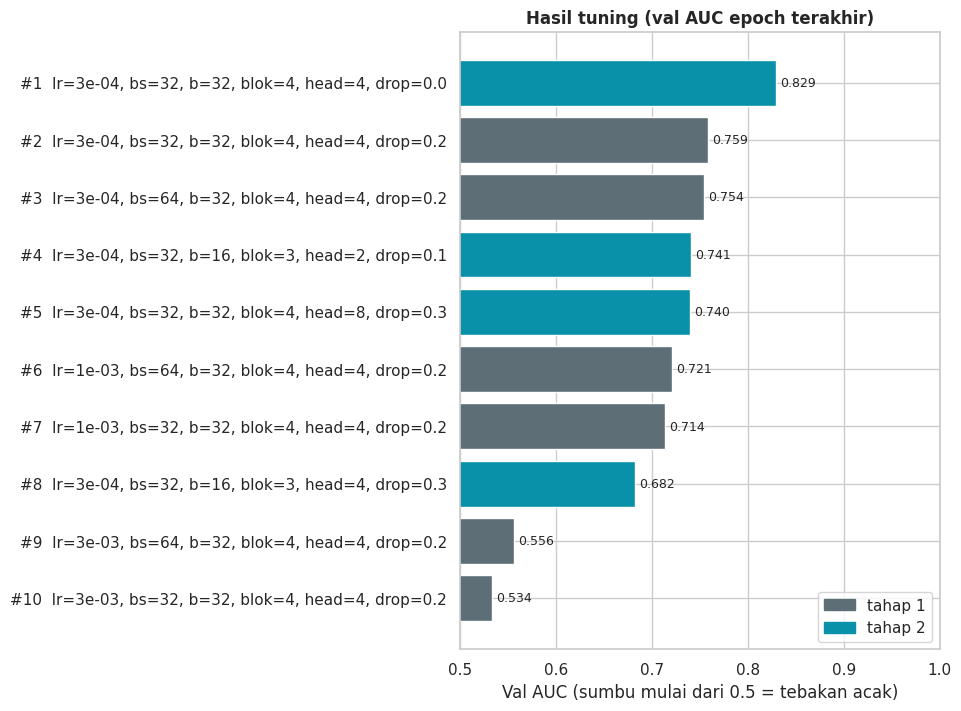

In [21]:
trials_df = pd.DataFrame(trial_results).sort_values("val_auc", ascending=False).reset_index(drop=True)
display(trials_df[["stage", "learning_rate", "batch_size", "base_filters", "num_blocks", "num_heads", "dropout",
                   "val_auc", "val_accuracy", "val_loss", "minutes"]]
        .style.format({"learning_rate": "{:.0e}", "dropout": "{:.1f}", "val_auc": "{:.4f}", "val_accuracy": "{:.4f}",
                       "val_loss": "{:.4f}", "minutes": "{:.1f}"}).hide(axis="index"))

best_trial = max(trial_results, key=lambda result: result["val_auc"])
best_params = {key: best_trial[key] for key in SEARCH_SPACE}
print("Konfigurasi terbaik:", best_params)
edge_keys = [key for key, values in SEARCH_SPACE.items()
             if len(values) >= 3 and best_params[key] in (min(values), max(values))]
if edge_keys:
    print("Perhatian: nilai terbaik berada di tepi rentang pencarian untuk", edge_keys,
          "-> pertimbangkan memperluas rentangnya.")

fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(trials_df) + 1.5), constrained_layout=True)
labels = [f"#{rank + 1}  lr={row.learning_rate:.0e}, bs={int(row.batch_size)}, b={int(row.base_filters)}, "
          f"blok={int(row.num_blocks)}, head={int(row.num_heads)}, drop={row.dropout}" for rank, row in trials_df.iterrows()]
stage_colors = {"tahap 1": MODEL_COLORS[0], "tahap 2": MODEL_COLORS[1]}
bars = ax.barh(labels[::-1], trials_df["val_auc"].to_numpy()[::-1],
               color=[stage_colors[stage] for stage in trials_df["stage"].to_numpy()[::-1]])
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set(title="Hasil tuning (val AUC epoch terakhir)", xlabel="Val AUC (sumbu mulai dari 0.5 = tebakan acak)", xlim=(0.5, 1.0))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color, label=stage) for stage, color in stage_colors.items()],
          loc="lower right")
plt.show()

**Catatan hasil tuning (run ini).** Pada batch 32, seperti run awal, learning rate 3e-4 menghasilkan val AUC 0,780, sedangkan 1e-3 hanya 0,656 dan 3e-3 nyaris tidak belajar (0,531). Pola yang sama muncul pada batch 64 (0,759; 0,703; 0,606). Ini searah dengan dugaan bahwa learning rate run awal (1e-3) terlalu besar untuk arsitektur ini, meski dengan anggaran tuning sekecil ini belum terbukti. Pada tahap 2, dropout 0,0 memberi val AUC 0,842 dibanding 0,780 untuk dropout 0,2 pada arsitektur yang sama.

Peringatan di atas muncul karena dua nilai terbaik berada di tepi rentang: dropout 0,0 adalah batas bawah alaminya, sedangkan learning rate di bawah 3e-4 tidak diuji, jadi optimum sebenarnya bisa sedikit lebih rendah. Skor tuning diambil setelah 5 epoch pada subset, yang cenderung memilih konfigurasi yang cepat belajar (regularisasi rendah). Karena training penuh sudah memenuhi target (Bagian 8), rentang tidak diperluas lagi; hal ini dicatat di Bagian 10.3.

### 7.4 Training Final: CNN Baseline vs CNN + MHSA
Konfigurasi terbaik hasil tuning dipakai untuk **kedua** model, dengan seed, urutan data, dan **jadwal learning rate yang persis sama** (warm-up lalu cosine decay, tidak bergantung pada metrik validasi). Pembeda satu-satunya adalah blok MHSA. `EarlyStopping` (pantau val AUC) hanya pengaman; bobot dengan val AUC terbaik dipulihkan di akhir training.

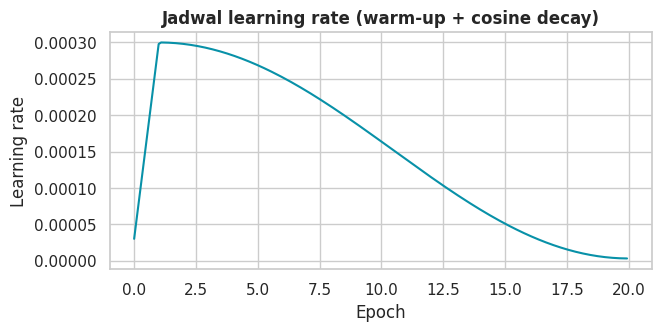

Epoch 1/20
625/625 - 75s - 120ms/step - accuracy: 0.6360 - auc: 0.6915 - loss: 0.6355 - precision: 0.6332 - recall: 0.6461 - val_accuracy: 0.6827 - val_auc: 0.7855 - val_loss: 0.5913 - val_precision: 0.8043 - val_recall: 0.4830
Epoch 2/20
625/625 - 69s - 111ms/step - accuracy: 0.7233 - auc: 0.7944 - loss: 0.5486 - precision: 0.7286 - recall: 0.7117 - val_accuracy: 0.7513 - val_auc: 0.8259 - val_loss: 0.5124 - val_precision: 0.7557 - val_recall: 0.7425
Epoch 3/20
625/625 - 73s - 117ms/step - accuracy: 0.7568 - auc: 0.8377 - loss: 0.4971 - precision: 0.7634 - recall: 0.7442 - val_accuracy: 0.7962 - val_auc: 0.8802 - val_loss: 0.4399 - val_precision: 0.8215 - val_recall: 0.7570
Epoch 4/20
625/625 - 69s - 111ms/step - accuracy: 0.7983 - auc: 0.8798 - loss: 0.4351 - precision: 0.8030 - recall: 0.7904 - val_accuracy: 0.7345 - val_auc: 0.8796 - val_loss: 0.5998 - val_precision: 0.6660 - val_recall: 0.9410
Epoch 5/20
625/625 - 69s - 111ms/step - accuracy: 0.8215 - auc: 0.9018 - loss: 0.3959 - 

In [22]:
MODEL_KEYS = ("base_filters", "num_blocks", "num_heads", "dropout")
model_kwargs = {key: best_params[key] for key in MODEL_KEYS}
STEPS_PER_EPOCH = int(np.ceil(len(train_df) / best_params["batch_size"]))


def build_and_compile(use_attention, name):
    """Model + optimizer dengan jadwal learning rate yang sama untuk baseline dan CNN + MHSA."""
    schedule = make_lr_schedule(best_params["learning_rate"], STEPS_PER_EPOCH, EPOCHS)
    return compile_model(build_model(use_attention, name=name, **model_kwargs), schedule)


def plot_lr_schedule():
    """Learning rate per langkah (identik untuk kedua model)."""
    schedule = make_lr_schedule(best_params["learning_rate"], STEPS_PER_EPOCH, EPOCHS)
    steps = np.arange(0, STEPS_PER_EPOCH * EPOCHS + 1, max(1, STEPS_PER_EPOCH // 10))
    fig, ax = plt.subplots(figsize=(6.5, 3.2), constrained_layout=True)
    ax.plot(steps / STEPS_PER_EPOCH, [float(schedule(step)) for step in steps], color=MODEL_COLORS[1])
    ax.set(title="Jadwal learning rate (warm-up + cosine decay)", xlabel="Epoch", ylabel="Learning rate")
    plt.show()


def train_model(model, tag):
    """Latih model pada seluruh data training dan kembalikan history-nya."""
    train_ds = make_dataset(train_df, best_params["batch_size"], training=True)     # shuffle dilakukan di tf.data
    val_ds = make_dataset(val_df, best_params["batch_size"], training=False)
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=make_callbacks(OUTPUT_DIR / f"{tag}_best.keras"), verbose=2)
    print(f"Selesai {tag}: {(time.time() - start) / 60:.1f} menit")
    return history


plot_lr_schedule()
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
baseline_model = build_and_compile(False, "cnn_baseline")
baseline_history = train_model(baseline_model, "cnn_baseline")

In [23]:
keras.utils.set_random_seed(SEED)
final_model = build_and_compile(True, "cnn_mhsa")
final_history = train_model(final_model, "cnn_mhsa")
histories = {"CNN baseline": baseline_history, "CNN + MHSA": final_history}

Epoch 1/20
625/625 - 78s - 125ms/step - accuracy: 0.6284 - auc: 0.6760 - loss: 0.6462 - precision: 0.6301 - recall: 0.6217 - val_accuracy: 0.5922 - val_auc: 0.7193 - val_loss: 0.6889 - val_precision: 0.7717 - val_recall: 0.2620
Epoch 2/20
625/625 - 71s - 114ms/step - accuracy: 0.7124 - auc: 0.7848 - loss: 0.5587 - precision: 0.7130 - recall: 0.7108 - val_accuracy: 0.7455 - val_auc: 0.8270 - val_loss: 0.5209 - val_precision: 0.8012 - val_recall: 0.6530
Epoch 3/20
625/625 - 71s - 114ms/step - accuracy: 0.7541 - auc: 0.8316 - loss: 0.5053 - precision: 0.7572 - recall: 0.7481 - val_accuracy: 0.7883 - val_auc: 0.8734 - val_loss: 0.4563 - val_precision: 0.7610 - val_recall: 0.8405
Epoch 4/20
625/625 - 71s - 114ms/step - accuracy: 0.7868 - auc: 0.8698 - loss: 0.4513 - precision: 0.7889 - recall: 0.7831 - val_accuracy: 0.7540 - val_auc: 0.8952 - val_loss: 0.5003 - val_precision: 0.6864 - val_recall: 0.9355
Epoch 5/20
625/625 - 82s - 132ms/step - accuracy: 0.8081 - auc: 0.8920 - loss: 0.4144 - 

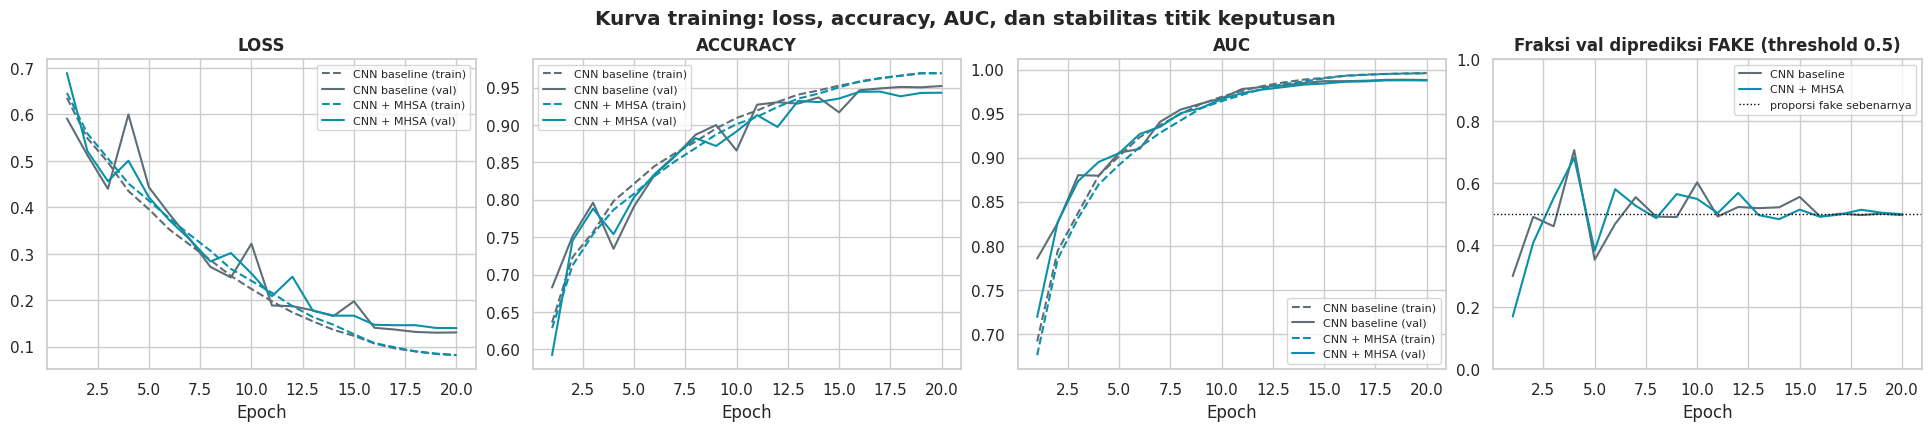

CNN baseline  | epoch terbaik: 19 | val_auc=0.9885 | val_acc=0.9505
CNN + MHSA    | epoch terbaik: 19 | val_auc=0.9879 | val_acc=0.9430


In [24]:
def val_fake_rate(history, positive_share):
    """Fraksi gambar validasi yang diprediksi fake pada threshold 0.5, dihitung dari precision dan recall:
    (TP + FP) / N = recall * positive_share / precision. Idealnya mendekati positive_share (0.5 untuk data seimbang)."""
    recall = np.asarray(history.history["val_recall"], dtype=float)
    precision = np.asarray(history.history["val_precision"], dtype=float)
    return recall * positive_share / np.clip(precision, 1e-9, None)


def plot_training_curves(histories_by_model, metrics=("loss", "accuracy", "auc")):
    """Kurva training (garis putus-putus) vs validasi (garis penuh) untuk tiap model.
    Panel terakhir: fraksi gambar validasi yang diprediksi fake, penanda titik keputusan yang bergeser."""
    fig, axes = plt.subplots(1, len(metrics) + 1, figsize=(4.8 * (len(metrics) + 1), 4.2), constrained_layout=True)
    for ax, metric in zip(axes, metrics):
        for (name, history), color in zip(histories_by_model.items(), MODEL_COLORS):
            epochs = range(1, len(history.history[metric]) + 1)
            ax.plot(epochs, history.history[metric], color=color, linestyle="--", label=f"{name} (train)")
            ax.plot(epochs, history.history[f"val_{metric}"], color=color, label=f"{name} (val)")
        ax.set(title=metric.upper(), xlabel="Epoch")
        ax.legend(fontsize=8)
    positive_share = float(val_df["label"].mean())
    for (name, history), color in zip(histories_by_model.items(), MODEL_COLORS):
        rate = val_fake_rate(history, positive_share)
        axes[-1].plot(range(1, len(rate) + 1), rate, color=color, label=name)
    axes[-1].axhline(positive_share, color="black", linestyle=":", linewidth=1, label="proporsi fake sebenarnya")
    axes[-1].set(title="Fraksi val diprediksi FAKE (threshold 0.5)", xlabel="Epoch", ylim=(0, 1))
    axes[-1].legend(fontsize=8)
    fig.suptitle("Kurva training: loss, accuracy, AUC, dan stabilitas titik keputusan", fontweight="bold")
    plt.show()


plot_training_curves(histories)
for name, history in histories.items():
    best_epoch = int(np.argmax(history.history["val_auc"]))
    print(f"{name:13s} | epoch terbaik: {best_epoch + 1:2d} | val_auc={history.history['val_auc'][best_epoch]:.4f} "
          f"| val_acc={history.history['val_accuracy'][best_epoch]:.4f}")

### 7.5 Uji Stabilitas Kurva
Sel berikut menghitung metrik yang sama seperti tabel di Bagian 7.2 dari run ini, sehingga perubahan bisa dibandingkan langsung. **Gerak naik-turun berlebih** dihitung per epoch (kurva yang naik mulus bernilai 0), dan fraksi gambar validasi yang diprediksi *fake* idealnya mendekati proporsi fake sebenarnya (0,5).

In [25]:
# Nilai run awal dihitung dari log training-nya (tabel di Bagian 7.2): 15 epoch, learning rate 1e-3 + ReduceLROnPlateau
OLD_RUN = {
    "CNN baseline": {"epochs": 15, "acc": 0.0241, "loss": 0.0406, "fake_range": (0.106, 0.939), "off": 8, "best_auc": 0.9011},
    "CNN + MHSA": {"epochs": 15, "acc": 0.0171, "loss": 0.0220, "fake_range": (0.198, 0.650), "off": 2, "best_auc": 0.9038},
}
FRACTION_LOW, FRACTION_HIGH = 0.35, 0.65     # fraksi prediksi fake yang masih dianggap wajar (idealnya 0.5)


def excess_variation(values):
    """Gerak naik-turun yang tidak ikut membentuk tren, per epoch. Kurva yang naik mulus bernilai 0."""
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return 0.0
    return float((np.abs(np.diff(values)).sum() - abs(values[-1] - values[0])) / (len(values) - 1))


def stability_report(histories_by_model):
    """Bandingkan run ini dengan run awal pada tiga ukuran. Vonis 'lebih stabil' menuntut ketiganya tidak lebih buruk,
    karena model yang selalu menebak satu kelas punya gerak naik-turun 0 padahal titik keputusannya rusak."""
    positive_share = float(val_df["label"].mean())
    rows, verdicts = [], []
    for name, history in histories_by_model.items():
        rate = val_fake_rate(history, positive_share)
        n_epochs = len(rate)
        new_acc = excess_variation(history.history["val_accuracy"])
        new_loss = excess_variation(history.history["val_loss"])
        n_off = int(((rate < FRACTION_LOW) | (rate > FRACTION_HIGH)).sum())
        new_auc = float(np.max(history.history["val_auc"]))
        old = OLD_RUN[name]
        rows.append({"model": name, "run": "awal", "epoch": old["epochs"],
                     "naik-turun val accuracy": old["acc"], "naik-turun val loss": old["loss"],
                     "fraksi fake val (min - maks)": f"{old['fake_range'][0]:.3f} - {old['fake_range'][1]:.3f}",
                     f"epoch di luar {FRACTION_LOW} - {FRACTION_HIGH}": f"{old['off']} dari {old['epochs']}",
                     "val AUC terbaik": old["best_auc"]})
        rows.append({"model": name, "run": "ini", "epoch": n_epochs,
                     "naik-turun val accuracy": new_acc, "naik-turun val loss": new_loss,
                     "fraksi fake val (min - maks)": f"{rate.min():.3f} - {rate.max():.3f}",
                     f"epoch di luar {FRACTION_LOW} - {FRACTION_HIGH}": f"{n_off} dari {n_epochs}",
                     "val AUC terbaik": new_auc})
        worse = [label for label, is_ok in (
            ("naik-turun val accuracy", new_acc <= old["acc"]),
            ("naik-turun val loss", new_loss <= old["loss"]),
            (f"porsi epoch di luar {FRACTION_LOW} - {FRACTION_HIGH}", n_off / n_epochs <= old["off"] / old["epochs"]),
        ) if not is_ok]
        verdict = ("lebih stabil daripada run awal pada ketiga ukuran." if not worse else
                   f"belum lebih stabil daripada run awal pada: {', '.join(worse)}. Periksa konfigurasi terpilih (Bagian 7.3).")
        verdicts.append(f"- **{name}:** {verdict}")
    display(pd.DataFrame(rows).style.format({"naik-turun val accuracy": "{:.4f}", "naik-turun val loss": "{:.4f}",
                                             "val AUC terbaik": "{:.4f}"}).hide(axis="index"))
    display(Markdown("\n".join(verdicts) + "\n\nKurva yang stabil belum tentu model yang baik: bandingkan juga kolom val AUC "
                     "terbaik dan hasil test di Bagian 8."))


stability_report(histories)

model,run,epoch,naik-turun val accuracy,naik-turun val loss,fraksi fake val (min - maks),epoch di luar 0.35 - 0.65,val AUC terbaik
CNN baseline,awal,15,0.0241,0.0406,0.106 - 0.939,8 dari 15,0.9011
CNN baseline,ini,20,0.0124,0.0279,0.300 - 0.707,2 dari 20,0.9885
CNN + MHSA,awal,15,0.0171,0.0220,0.198 - 0.650,2 dari 15,0.9038
CNN + MHSA,ini,20,0.0072,0.0110,0.170 - 0.682,2 dari 20,0.9879


- **CNN baseline:** lebih stabil daripada run awal pada ketiga ukuran.
- **CNN + MHSA:** lebih stabil daripada run awal pada ketiga ukuran.

Kurva yang stabil belum tentu model yang baik: bandingkan juga kolom val AUC terbaik dan hasil test di Bagian 8.

**Catatan hasil uji stabilitas (run ini).** Pada CNN baseline, naik-turun val accuracy turun dari 0,0241 menjadi 0,0026, dan epoch dengan fraksi prediksi fake di luar 0,35 – 0,65 turun dari 8 dari 15 menjadi 1 dari 20. CNN + MHSA membaik lebih sedikit: 0,0171 menjadi 0,0082, dengan 2 dari 20 epoch di luar rentang. Val AUC terbaik juga naik dari sekitar 0,90 menjadi 0,988 untuk keduanya, jadi kurva yang lebih stabil ini bukan akibat model berhenti belajar.

Sisa ketidakstabilan terkumpul di awal training. Pada CNN + MHSA, fraksi fake validasi masih berayun antara 0,13 dan 0,61 selama enam epoch pertama, ditambah satu penurunan sesaat di epoch 12 (val accuracy 0,904 menjadi 0,890, lalu 0,923 di epoch 13). Pada lima epoch terakhir fraksi itu bertahan di 0,49 – 0,51 untuk kedua model. Pola ini konsisten dengan dugaan di Bagian 7.2 (bobot berubah cepat di awal sementara statistik BatchNorm tertinggal, lalu keduanya menetap saat learning rate turun), tetapi dugaan itu belum diuji terpisah pada data asli, dan resep baru (learning rate, momentum BatchNorm, jadwal) dinilai sebagai satu paket.

---
## 8. Model Evaluation

Seluruh evaluasi di bagian ini memakai **data test** yang tidak pernah dipakai untuk training maupun tuning. Satu-satunya pengecualian adalah pemilihan *threshold* keputusan, yang dipilih dari **data validasi**.

Kelas positif = **fake**. Jadi *recall* berarti "dari semua wajah palsu, berapa persen yang berhasil terdeteksi", dan *precision* berarti "dari semua gambar yang diprediksi palsu, berapa persen yang benar-benar palsu".

In [26]:
def predict_probabilities(model, df, batch_size=128):
    """P(fake) untuk setiap gambar pada dataframe (urutan baris dipertahankan)."""
    return model.predict(make_dataset(df, batch_size, training=False), verbose=0).ravel()


def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "auc": roc_auc_score(y_true, y_prob)}


def select_threshold(y_true, y_prob):
    """Threshold yang memaksimalkan F1 pada data validasi."""
    thresholds = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    return round(float(thresholds[int(np.argmax(scores))]), 2)


y_true = test_df["label"].to_numpy()
val_true = val_df["label"].to_numpy()
trained_models = {"CNN baseline": baseline_model, "CNN + MHSA": final_model}
test_probs = {name: predict_probabilities(model, test_df) for name, model in trained_models.items()}
val_probs = {name: predict_probabilities(model, val_df) for name, model in trained_models.items()}

# Threshold tiap model dipilih dari data VALIDASI (bukan test), supaya perbandingan tidak bergantung pada
# titik keputusan 0.5 yang bisa bergeser antar model (lihat Bagian 7.2)
THRESHOLDS = {name: select_threshold(val_true, prob) for name, prob in val_probs.items()}
THRESHOLD = THRESHOLDS["CNN + MHSA"]             # threshold model final (dipakai API dan Streamlit)
BASE_THRESHOLD = THRESHOLDS["CNN baseline"]
BASE_ROW = f"CNN baseline (threshold {BASE_THRESHOLD:.2f})"
FINAL_ROW = f"CNN + MHSA (threshold {THRESHOLD:.2f})"
results_df = pd.DataFrame({
    "CNN baseline (threshold 0.50)": compute_metrics(y_true, test_probs["CNN baseline"]),
    BASE_ROW: compute_metrics(y_true, test_probs["CNN baseline"], BASE_THRESHOLD),
    "CNN + MHSA (threshold 0.50)": compute_metrics(y_true, test_probs["CNN + MHSA"]),
    FINAL_ROW: compute_metrics(y_true, test_probs["CNN + MHSA"], THRESHOLD),
}).T
display(results_df.style.format("{:.4f}").highlight_max(axis=0, color="#CDEFF5"))

target_check = pd.DataFrame({"hasil": results_df.loc[FINAL_ROW, list(TARGETS)], "target": pd.Series(TARGETS)})
target_check["status"] = np.where(target_check["hasil"] >= target_check["target"], "Tercapai", "Belum tercapai")
display(target_check.style.format({"hasil": "{:.4f}", "target": "{:.2f}"}))
print(classification_report(y_true, (test_probs["CNN + MHSA"] >= THRESHOLD).astype(int), target_names=CLASS_NAMES, digits=4))

,accuracy,precision,recall,f1,auc
CNN baseline (threshold 0.50),0.9458,0.9417,0.9504,0.9460,0.9888
CNN baseline (threshold 0.58),0.9473,0.9525,0.9416,0.9470,0.9888
CNN + MHSA (threshold 0.50),0.9391,0.9331,0.9460,0.9395,0.9865
CNN + MHSA (threshold 0.60),0.9395,0.9438,0.9346,0.9392,0.9865


,hasil,target,status
accuracy,0.9395,0.90,Tercapai
precision,0.9438,0.90,Tercapai
recall,0.9346,0.90,Tercapai
f1,0.9392,0.90,Tercapai
auc,0.9865,0.95,Tercapai


              precision    recall  f1-score   support

        real     0.9352    0.9444    0.9398      5000
        fake     0.9438    0.9346    0.9392      5000

    accuracy                         0.9395     10000
   macro avg     0.9395    0.9395    0.9395     10000
weighted avg     0.9395    0.9395    0.9395     10000



In [27]:
def bootstrap_ci(y_true_values, y_prob_values, metric_fn, n_boot=N_BOOTSTRAP, alpha=0.05):
    """Interval kepercayaan bootstrap persentil untuk sebuah metrik."""
    rng = np.random.default_rng(SEED)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true_values), len(y_true_values))
        if len(np.unique(y_true_values[idx])) == 2:
            scores.append(metric_fn(y_true_values[idx], y_prob_values[idx]))
    return np.percentile(scores, [100 * alpha / 2, 100 * (1 - alpha / 2)])


def paired_bootstrap_diff(y_true_values, prob_a, prob_b, metric_fn, n_boot=N_BOOTSTRAP, alpha=0.05):
    """Selisih metrik (model B - model A) dan CI bootstrap berpasangan: sampel gambar yang sama dipakai untuk
    kedua model, jadi hasilnya tidak bergantung pada threshold bila metric_fn berbasis peringkat (AUC)."""
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true_values), len(y_true_values))
        if len(np.unique(y_true_values[idx])) == 2:
            diffs.append(metric_fn(y_true_values[idx], prob_b[idx]) - metric_fn(y_true_values[idx], prob_a[idx]))
    return float(metric_fn(y_true_values, prob_b) - metric_fn(y_true_values, prob_a)), \
        np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])


def mcnemar_exact(y_true_values, pred_a, pred_b):
    """Uji McNemar exact: apakah dua model memiliki pola kesalahan yang berbeda secara signifikan?"""
    correct_a, correct_b = pred_a == y_true_values, pred_b == y_true_values
    only_a, only_b = int((correct_a & ~correct_b).sum()), int((~correct_a & correct_b).sum())
    p_value = 1.0 if only_a + only_b == 0 else stats.binomtest(only_a, only_a + only_b, 0.5).pvalue
    return only_a, only_b, p_value


final_prob = test_probs["CNN + MHSA"]
base_prob = test_probs["CNN baseline"]
accuracy_ci = bootstrap_ci(y_true, final_prob, lambda yt, yp: accuracy_score(yt, (yp >= THRESHOLD).astype(int)))
auc_ci = bootstrap_ci(y_true, final_prob, roc_auc_score)

# Ablation: (a) threshold 0.5 untuk keduanya, (b) threshold masing-masing model dari validasi, (c) AUC tanpa threshold
only_base, only_mhsa, mcnemar_p = mcnemar_exact(
    y_true, (base_prob >= 0.5).astype(int), (final_prob >= 0.5).astype(int))
only_base_own, only_mhsa_own, mcnemar_p_own = mcnemar_exact(
    y_true, (base_prob >= BASE_THRESHOLD).astype(int), (final_prob >= THRESHOLD).astype(int))
auc_diff, auc_diff_ci = paired_bootstrap_diff(y_true, base_prob, final_prob, roc_auc_score)


def ablation_verdict():
    """Kesimpulan ablation dari tiga ukuran di atas, plus catatan bila temuan di threshold 0.5 tidak didukung ukuran lain."""
    own_significant = mcnemar_p_own < 0.05
    mhsa_better_own = only_mhsa_own > only_base_own
    auc_better, auc_worse = auc_diff_ci[0] > 0, auc_diff_ci[1] < 0
    mhsa_wins = own_significant and mhsa_better_own and auc_better
    baseline_wins = own_significant and not mhsa_better_own and auc_worse
    if mhsa_wins:
        verdict = "attention memberi peningkatan yang signifikan (accuracy pada threshold masing-masing dan AUC)"
    elif baseline_wins:
        verdict = "CNN baseline justru signifikan lebih baik (accuracy pada threshold masing-masing dan AUC)"
    elif not own_significant and not auc_better and not auc_worse:
        verdict = "tidak ada bukti perbedaan yang signifikan antara kedua model pada konfigurasi ini"
    else:
        verdict = "buktinya campuran antara accuracy dan AUC (lihat angka di atas)"
    # Catatan hanya bila McNemar di threshold 0.5 signifikan tetapi pemenangnya tidak sejalan dengan vonis di atas
    winner_at_default = "mhsa" if only_mhsa > only_base else "baseline"
    corroborated = (mhsa_wins and winner_at_default == "mhsa") or (baseline_wins and winner_at_default == "baseline")
    note = ""
    if mcnemar_p < 0.05 and not corroborated:
        note = (" Selisih accuracy yang tampak signifikan pada threshold 0.5 lebih mencerminkan titik keputusan yang "
                "berbeda antar model daripada kemampuan memisahkan kelas.")
    return verdict, note


print(f"CNN + MHSA | accuracy 95% CI: [{accuracy_ci[0]:.4f}, {accuracy_ci[1]:.4f}] | AUC 95% CI: [{auc_ci[0]:.4f}, {auc_ci[1]:.4f}]")
print(f"McNemar (threshold 0.5 untuk keduanya): benar hanya di baseline = {only_base}, benar hanya di MHSA = {only_mhsa}, p-value = {mcnemar_p:.4g}")
print(f"McNemar (threshold masing-masing: baseline {BASE_THRESHOLD:.2f}, MHSA {THRESHOLD:.2f}): "
      f"benar hanya di baseline = {only_base_own}, benar hanya di MHSA = {only_mhsa_own}, p-value = {mcnemar_p_own:.4g}")
print(f"Selisih AUC (MHSA - baseline) = {auc_diff:+.4f} | 95% CI bootstrap berpasangan: [{auc_diff_ci[0]:+.4f}, {auc_diff_ci[1]:+.4f}]")
verdict_text, verdict_note = ablation_verdict()
print(f"Kesimpulan: {verdict_text}.{verdict_note}")

CNN + MHSA | accuracy 95% CI: [0.9349, 0.9439] | AUC 95% CI: [0.9848, 0.9880]
McNemar (threshold 0.5 untuk keduanya): benar hanya di baseline = 326, benar hanya di MHSA = 259, p-value = 0.006309
McNemar (threshold masing-masing: baseline 0.58, MHSA 0.60): benar hanya di baseline = 310, benar hanya di MHSA = 232, p-value = 0.0009246
Selisih AUC (MHSA - baseline) = -0.0024 | 95% CI bootstrap berpasangan: [-0.0037, -0.0010]
Kesimpulan: CNN baseline justru signifikan lebih baik (accuracy pada threshold masing-masing dan AUC).


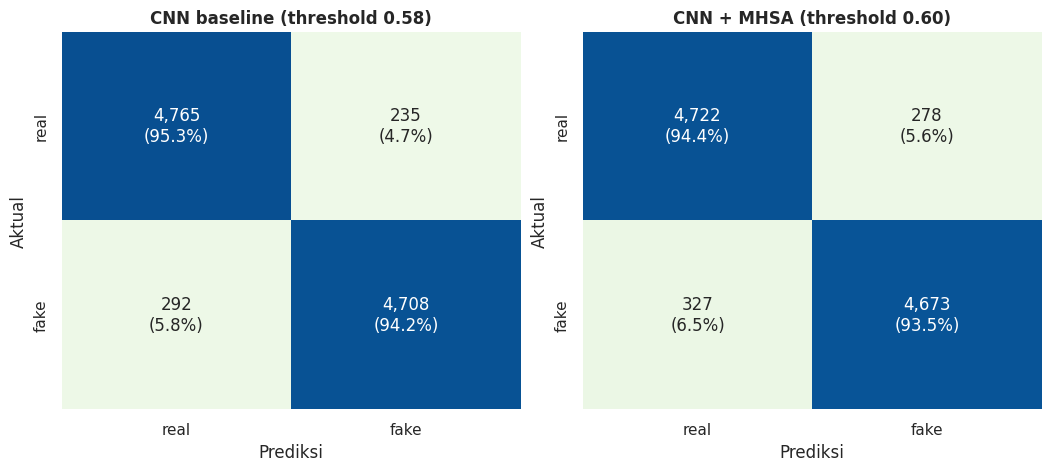

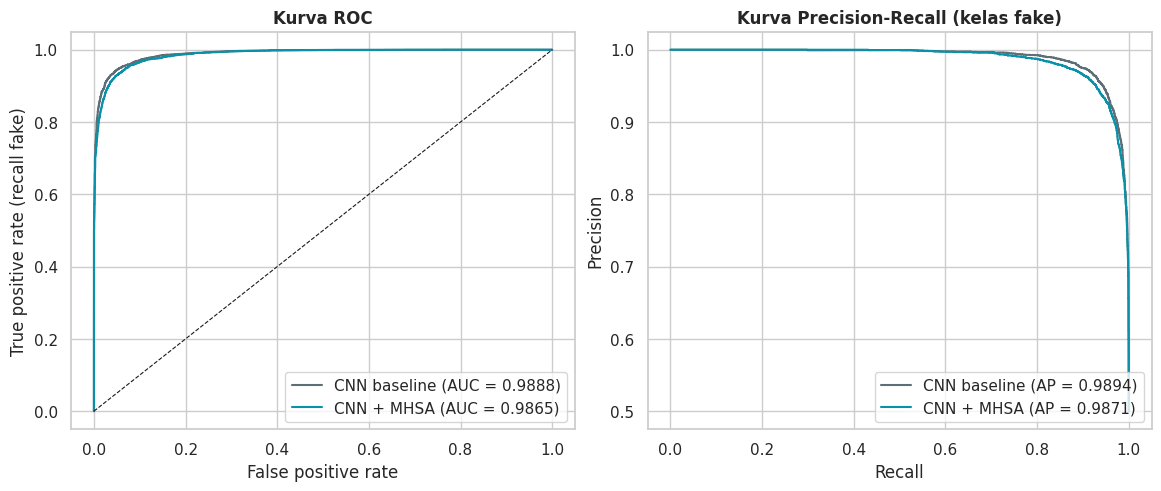

In [28]:
def plot_confusion_matrices(y_true_values, predictions):
    """Confusion matrix (jumlah dan persentase per baris) untuk beberapa model."""
    fig, axes = plt.subplots(1, len(predictions), figsize=(5.2 * len(predictions), 4.6), constrained_layout=True)
    for ax, (name, y_pred) in zip(np.atleast_1d(axes), predictions.items()):
        counts = confusion_matrix(y_true_values, y_pred, labels=[0, 1])
        percent = counts / counts.sum(axis=1, keepdims=True)
        notes = np.array([[f"{counts[i, j]:,}\n({percent[i, j]:.1%})" for j in range(2)] for i in range(2)])
        sns.heatmap(percent, annot=notes, fmt="", cmap="GnBu", vmin=0, vmax=1, cbar=False,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
        ax.set(title=name, xlabel="Prediksi", ylabel="Aktual")
    plt.show()


def plot_roc_pr(y_true_values, probabilities):
    """Kurva ROC dan Precision-Recall (kelas fake) untuk beberapa model."""
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
    for (name, prob), color in zip(probabilities.items(), MODEL_COLORS):
        fpr, tpr, _ = roc_curve(y_true_values, prob)
        precision, recall, _ = precision_recall_curve(y_true_values, prob)
        axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC = {roc_auc_score(y_true_values, prob):.4f})")
        axes[1].plot(recall, precision, color=color, label=f"{name} (AP = {average_precision_score(y_true_values, prob):.4f})")
    axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
    axes[0].set(title="Kurva ROC", xlabel="False positive rate", ylabel="True positive rate (recall fake)")
    axes[1].set(title="Kurva Precision-Recall (kelas fake)", xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.legend(loc="lower right")
    plt.show()


plot_confusion_matrices(y_true, {BASE_ROW: (base_prob >= BASE_THRESHOLD).astype(int),
                                 FINAL_ROW: (final_prob >= THRESHOLD).astype(int)})
plot_roc_pr(y_true, test_probs)

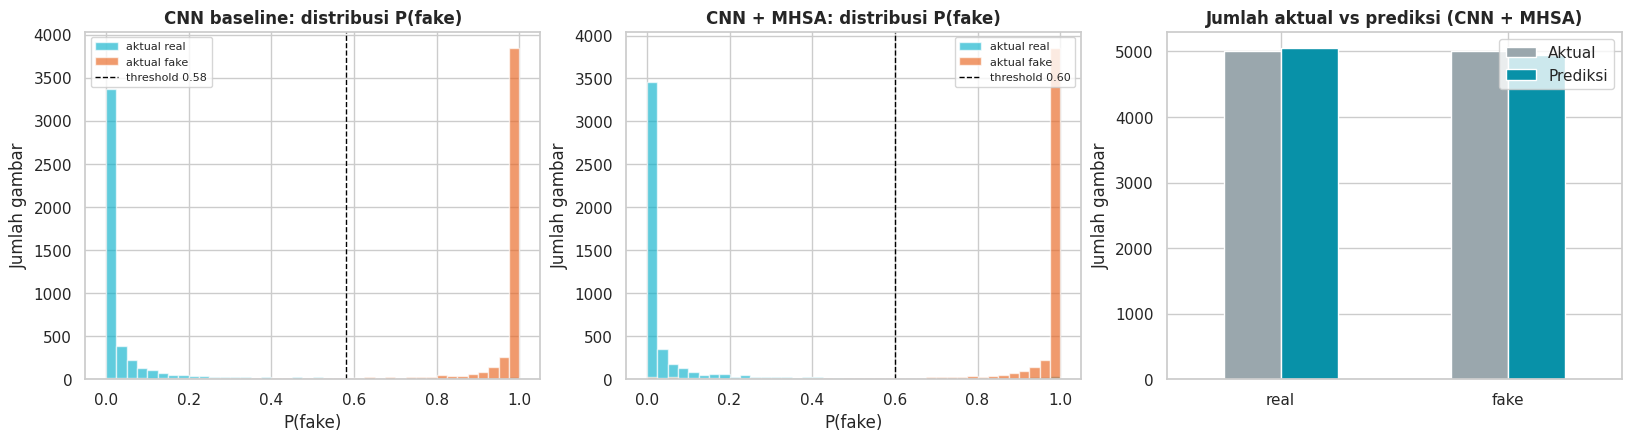

In [29]:
def plot_prediction_distribution(y_true_values, probabilities, thresholds):
    """Aktual vs prediksi: distribusi P(fake) per kelas aktual dan perbandingan jumlah aktual vs prediksi."""
    fig, axes = plt.subplots(1, len(probabilities) + 1, figsize=(5.4 * (len(probabilities) + 1), 4.3), constrained_layout=True)
    for ax, (name, prob) in zip(axes, probabilities.items()):
        threshold = thresholds[name]
        for class_name, idx in CLASS_TO_IDX.items():
            ax.hist(prob[y_true_values == idx], bins=40, range=(0, 1), alpha=0.65, color=PALETTE[class_name],
                    label=f"aktual {class_name}")
        ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label=f"threshold {threshold:.2f}")
        ax.set(title=f"{name}: distribusi P(fake)", xlabel="P(fake)", ylabel="Jumlah gambar")
        ax.legend(fontsize=8)
    final_pred = (probabilities["CNN + MHSA"] >= thresholds["CNN + MHSA"]).astype(int)
    counts = pd.DataFrame({"Aktual": np.bincount(y_true_values, minlength=2),
                           "Prediksi": np.bincount(final_pred, minlength=2)}, index=CLASS_NAMES)
    counts.plot.bar(ax=axes[-1], color=["#9AA7AD", "#0891A8"], rot=0)
    axes[-1].set(title="Jumlah aktual vs prediksi (CNN + MHSA)", ylabel="Jumlah gambar")
    plt.show()


plot_prediction_distribution(y_true, test_probs, THRESHOLDS)

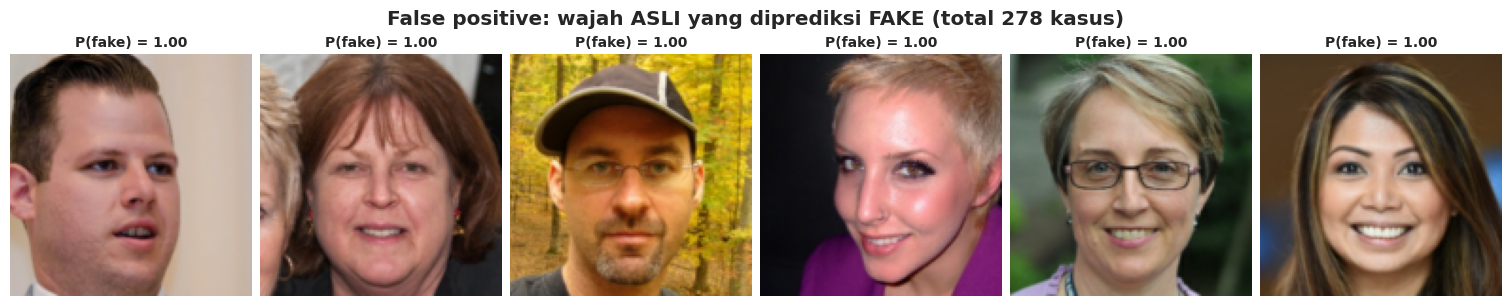

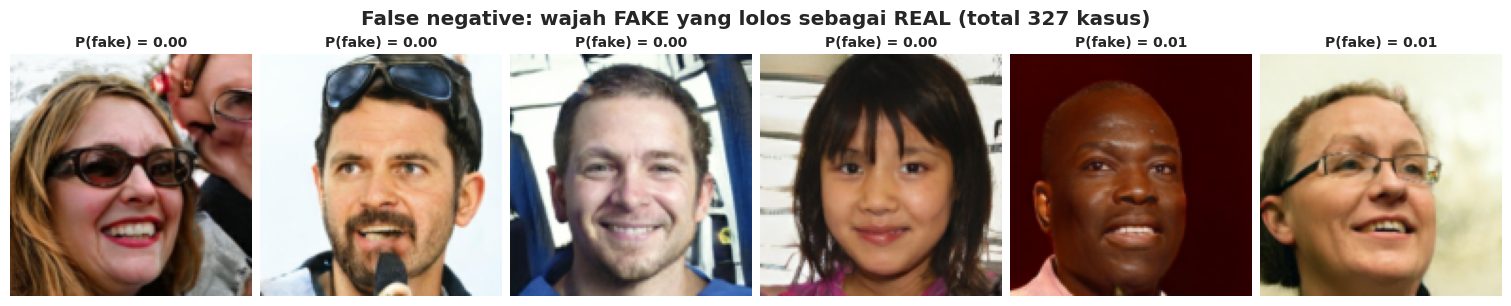

In [30]:
def load_model_input(path):
    """Gambar dengan preprocessing yang sama persis dengan pipeline training (skala 0-255)."""
    image, _ = load_and_resize(tf.constant(path), tf.constant(0.0))
    return image.numpy()


def show_error_cases(mask, probabilities, title, n=6, most_confident_high=True):
    """Tampilkan kesalahan prediksi dengan tingkat keyakinan terbesar."""
    candidates = np.where(mask)[0]
    if len(candidates) == 0:
        print(f"{title}: tidak ada kasus.")
        return
    order = candidates[np.argsort(probabilities[candidates])]
    chosen = (order[::-1] if most_confident_high else order)[:n]
    fig, axes = plt.subplots(1, len(chosen), figsize=(2.5 * len(chosen), 3.1), constrained_layout=True)
    for ax, idx in zip(np.atleast_1d(axes), chosen):
        ax.imshow(load_model_input(test_df.iloc[idx]["path"]).astype("uint8"))
        ax.set_title(f"P(fake) = {probabilities[idx]:.2f}", fontsize=10)
        ax.axis("off")
    fig.suptitle(f"{title} (total {len(candidates):,} kasus)", fontweight="bold")
    plt.show()


final_pred = (final_prob >= THRESHOLD).astype(int)
show_error_cases((y_true == 0) & (final_pred == 1), final_prob,
                 "False positive: wajah ASLI yang diprediksi FAKE", most_confident_high=True)
show_error_cases((y_true == 1) & (final_pred == 0), final_prob,
                 "False negative: wajah FAKE yang lolos sebagai REAL", most_confident_high=False)

### 8.2 Explainability: Grad-CAM
Grad-CAM menunjukkan **wilayah gambar yang paling mendorong keputusan model** (terang = pengaruh besar terhadap P(fake)). Ini cara memeriksa apakah model melihat area wajah yang masuk akal atau justru memanfaatkan artefak latar. Metode yang sama dipakai pada paper 1 (attention heatmap) dan paper 2 (Grad-CAM).

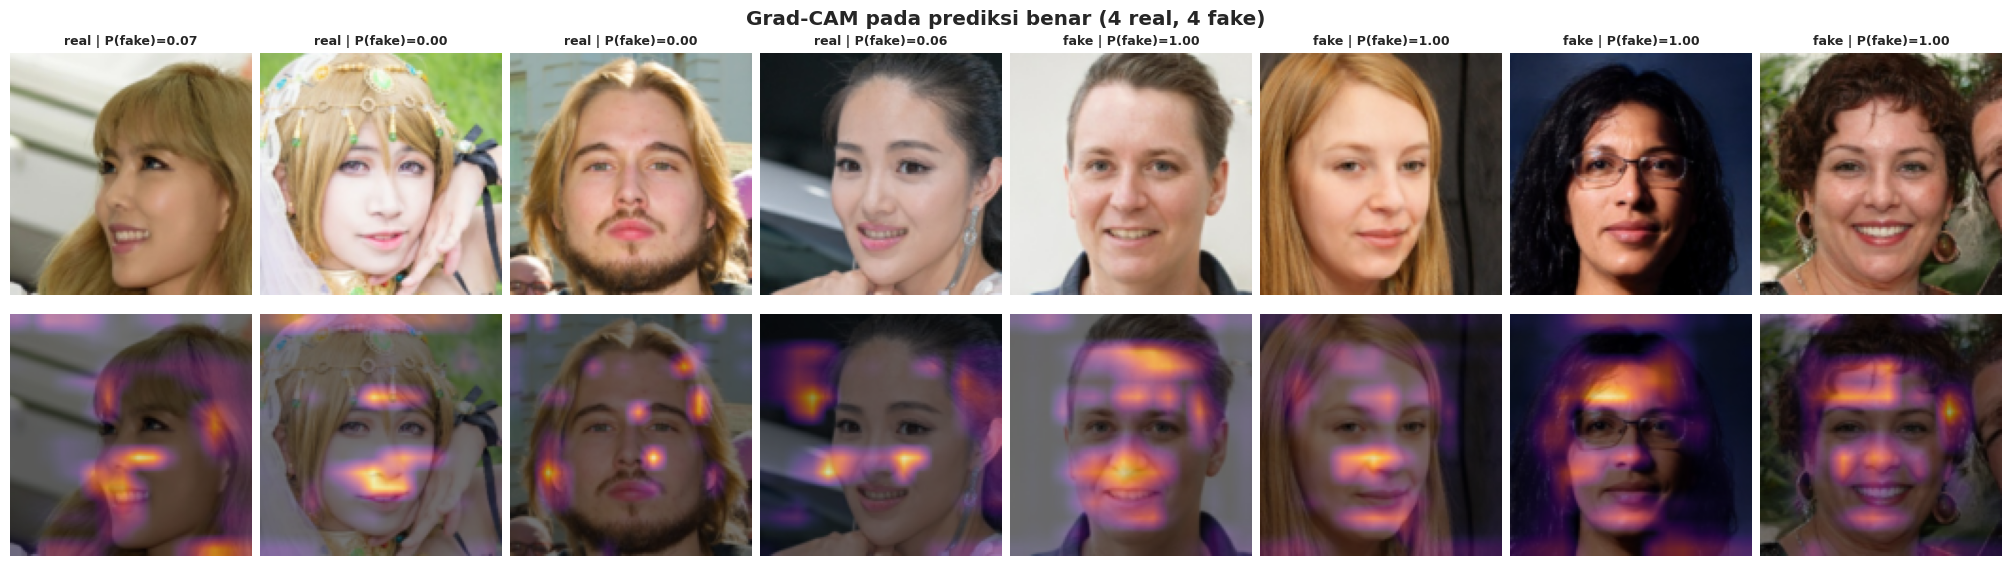

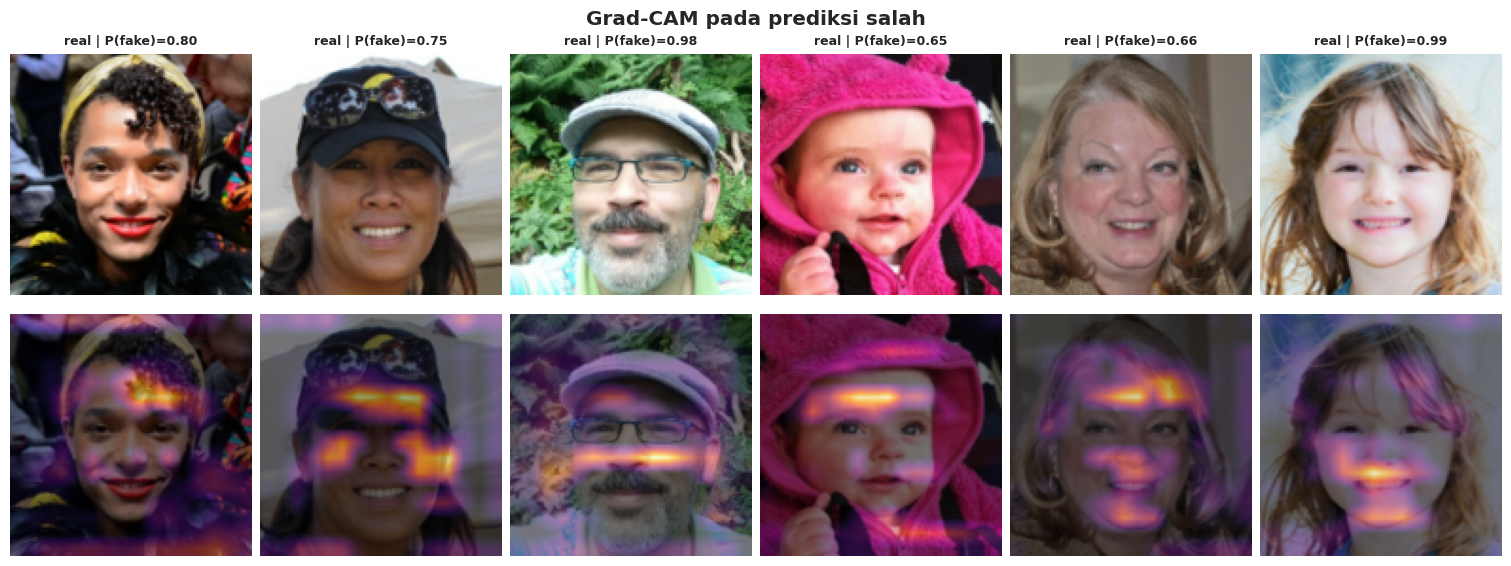

In [31]:
def build_gradcam_model(model, num_blocks):
    """Model yang mengembalikan feature map konvolusi terakhir dan prediksi."""
    target_layer = model.get_layer(f"block{num_blocks}_relu2").output
    return keras.Model(model.inputs, [target_layer, model.output])


def compute_gradcam(grad_model, images):
    """Heatmap Grad-CAM (N, h, w) ternormalisasi 0-1 untuk batch gambar skala 0-255."""
    with tf.GradientTape() as tape:
        features, predictions = grad_model(tf.convert_to_tensor(images, tf.float32), training=False)
        score = predictions[:, 0]
    gradients = tape.gradient(score, features)
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * features, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    return cam.numpy()


def show_gradcam_grid(indices, probabilities, title):
    """Baris atas: gambar asli. Baris bawah: overlay Grad-CAM."""
    if len(indices) == 0:
        print(f"{title}: tidak ada contoh.")
        return
    grad_model = build_gradcam_model(final_model, best_params["num_blocks"])
    images = np.stack([load_model_input(test_df.iloc[i]["path"]) for i in indices])
    heatmaps = compute_gradcam(grad_model, images)
    fig, axes = plt.subplots(2, len(indices), figsize=(2.5 * len(indices), 5.6), constrained_layout=True, squeeze=False)
    for col, idx in enumerate(indices):
        heat = tf.image.resize(heatmaps[col][..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
        axes[0, col].imshow(images[col].astype("uint8"))
        axes[0, col].set_title(f"{CLASS_NAMES[int(y_true[idx])]} | P(fake)={probabilities[idx]:.2f}", fontsize=9)
        axes[1, col].imshow(images[col].astype("uint8"))
        axes[1, col].imshow(heat, cmap="inferno", alpha=0.55)
        axes[0, col].axis("off")
        axes[1, col].axis("off")
    fig.suptitle(title, fontweight="bold")
    plt.show()


rng = np.random.default_rng(SEED)
correct_real = np.where((y_true == 0) & (final_pred == 0))[0]
correct_fake = np.where((y_true == 1) & (final_pred == 1))[0]
picked = np.concatenate([rng.choice(correct_real, min(4, len(correct_real)), replace=False),
                         rng.choice(correct_fake, min(4, len(correct_fake)), replace=False)]).astype(int)
show_gradcam_grid(picked, final_prob, "Grad-CAM pada prediksi benar (4 real, 4 fake)")

wrong = np.where(y_true != final_pred)[0]
show_gradcam_grid(wrong[:6], final_prob, "Grad-CAM pada prediksi salah")

**Catatan pembacaan Grad-CAM (run ini).**

1. **Pita terang di tepi atas.** Pada seluruh 14 heatmap di atas (8 prediksi benar dan 6 prediksi salah, real maupun fake), wilayah paling terang selalu berupa pita tipis di tepi paling atas gambar. Pola serupa pada semua gambar dan kedua kelas menunjukkan ini bisa berasal dari efek tepi feature map (padding) atau dari ciri tepi atas gambar pada dataset, dan belum tentu dari bagian wajah. Karena itu Grad-CAM di sini belum bisa dipakai untuk menjawab pertanyaan bisnis 4 (bagian wajah mana yang paling berpengaruh). Apakah model benar-benar memanfaatkan tepi atas belum diuji.
2. **Di bawah pita itu**, panas tampak tersebar di sekitar dahi atau alis, hidung, dan mulut pada sebagian contoh, tanpa perbedaan pola yang jelas antara real dan fake. Ini kesan visual dari sedikit contoh, bukan hasil kuantitatif.
3. **Panel "prediksi salah" hanya memuat false positive** (real yang diprediksi fake). Data test terurut per kelas dan sel hanya mengambil enam kesalahan pertama menurut indeks, padahal kesalahan yang lebih banyak adalah false negative (383 dibanding 209 false positive). Contoh false negative ada di Bagian 8.1.

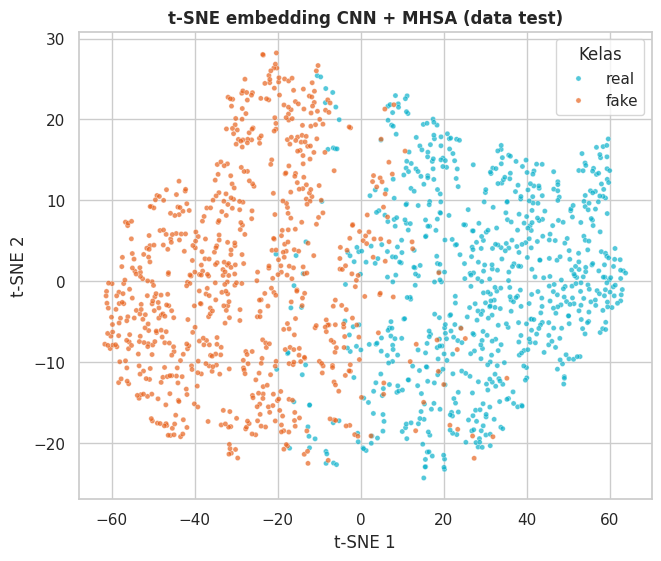

In [32]:
def plot_embedding_tsne(model, df, n_per_class):
    """Proyeksi t-SNE dari embedding (layer Dense 128) pada sampel data test."""
    sample = stratified_sample(df, n_per_class)
    embedder = keras.Model(model.inputs, model.get_layer("embedding").output)
    embeddings = embedder.predict(make_dataset(sample, 128, training=False), verbose=0)
    perplexity = max(2, min(30, (len(sample) - 1) // 3))
    coords = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED).fit_transform(embeddings)
    fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=sample["label_str"], hue_order=CLASS_NAMES,
                    palette=PALETTE, s=14, alpha=0.7, ax=ax)
    ax.set(title="t-SNE embedding CNN + MHSA (data test)", xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(title="Kelas")
    plt.show()


plot_embedding_tsne(final_model, test_df, TSNE_N_PER_CLASS)

### 8.3 Uji Ketahanan (Robustness)
Di dunia nyata, gambar jarang dikirim dalam kondisi "bersih": foto dikompresi ulang oleh aplikasi, diperkecil, atau sedikit buram. Sel berikut mengukur seberapa besar performa model turun pada degradasi umum tersebut. Ini menjawab pertanyaan bisnis nomor 3 dan menjadi dasar rekomendasi pada Bagian 10.

| Kondisi | Perlakuan pada gambar test |
|---|---|
| `clean` | Tanpa perubahan (pembanding) |
| `jpeg_q50` | Kompresi ulang JPEG kualitas 50 |
| `blur_r1` | Gaussian blur radius 1 piksel |
| `downscale_x0.5` | Diperkecil 50% lalu dibesarkan kembali |

Uji ketahanan:   0%|          | 0/4 [00:00<?, ?it/s]

kondisi,accuracy,recall_fake,recall_real
clean,0.9290,0.9260,0.9320
jpeg_q50,0.8950,0.8520,0.9380
blur_r1,0.9320,0.9280,0.9360
downscale_x0.5,0.9360,0.9220,0.9500


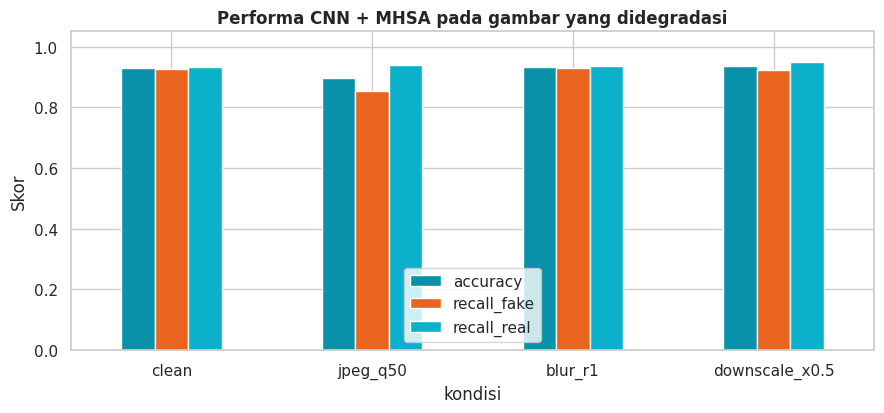

In [33]:
PERTURBATIONS = ["clean", "jpeg_q50", "blur_r1", "downscale_x0.5"]


def perturb_image(image, kind):
    """Degradasi gambar PIL (RGB) sesuai jenisnya."""
    if kind == "clean":
        return image
    if kind == "jpeg_q50":
        buffer = BytesIO()
        image.save(buffer, format="JPEG", quality=50)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")
    if kind == "blur_r1":
        return image.filter(ImageFilter.GaussianBlur(radius=1.0))
    if kind == "downscale_x0.5":
        width, height = image.size
        small = image.resize((width // 2, height // 2), Image.Resampling.BILINEAR)
        return small.resize((width, height), Image.Resampling.BILINEAR)
    raise ValueError(f"Perlakuan tidak dikenal: {kind}")


def predict_perturbed(model, paths, kind, batch_size=64):
    """P(fake) untuk gambar yang sudah didegradasi, dengan resize yang sama seperti pipeline training."""
    outputs = []
    for start in range(0, len(paths), batch_size):
        batch = []
        for path in paths[start:start + batch_size]:
            image = perturb_image(Image.open(path).convert("RGB"), kind)
            resized = tf.image.resize(np.asarray(image), (IMG_SIZE, IMG_SIZE), method="bilinear", antialias=True)
            batch.append(resized.numpy())
        outputs.append(model.predict(np.stack(batch), verbose=0).ravel())
    return np.concatenate(outputs)


robust_sample = stratified_sample(test_df, ROBUST_N_PER_CLASS)
robust_true = robust_sample["label"].to_numpy()
robust_rows = []
for kind in tqdm(PERTURBATIONS, desc="Uji ketahanan"):
    pred = (predict_perturbed(final_model, robust_sample["path"].tolist(), kind) >= THRESHOLD).astype(int)
    robust_rows.append({"kondisi": kind,
                        "accuracy": accuracy_score(robust_true, pred),
                        "recall_fake": recall_score(robust_true, pred, pos_label=1, zero_division=0),
                        "recall_real": recall_score(robust_true, pred, pos_label=0, zero_division=0)})
robust_df = pd.DataFrame(robust_rows)
display(robust_df.style.format({"accuracy": "{:.4f}", "recall_fake": "{:.4f}", "recall_real": "{:.4f}"}).hide(axis="index"))

ax = robust_df.set_index("kondisi")[["accuracy", "recall_fake", "recall_real"]].plot.bar(
    figsize=(9, 4.3), rot=0, color=["#0891A8", "#E8641F", "#0BB1CB"])
ax.set(title="Performa CNN + MHSA pada gambar yang didegradasi", ylabel="Skor", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

**Catatan hasil uji ketahanan (run ini).** Sampel uji ini kecil (500 gambar per kelas): accuracy `clean` di sini 92,7% dibanding 94,1% pada seluruh data test, jadi angka per kondisi dibaca sebagai gambaran kasar (galat baku sekitar 0,8 poin). Penurunan accuracy terbesar adalah 1,8 poin (JPEG q50), tetapi komposisinya tidak seimbang: recall fake turun dari 91,4% menjadi 86,0% sementara recall real naik dari 94,0% menjadi 95,8%. Artinya gambar palsu yang terkompresi lebih mudah lolos sebagai asli. Arah yang sama terlihat pada downscale (recall fake 89,2%) dan blur (90,8%), walau pada blur selisihnya hanya sekitar 3 dari 500 gambar. Karena fake yang lolos adalah kesalahan yang paling merugikan (Bagian 1.5), ukuran yang perlu dipantau pada gambar terkompresi adalah recall fake, bukan accuracy.

---
## 9. Penyimpanan Model dan Persiapan Deployment

Guideline langkah 6 meminta model di-deploy sebagai REST API (Flask/FastAPI), disimpan di private repository GitHub dengan CI/CD (GitHub Actions), dan hasil prediksi diintegrasikan dengan database. Kode API, database, dan CI/CD dibuat terpisah di repo. Bagian ini menghasilkan **artefak yang dibutuhkan** oleh langkah tersebut:

| Artefak | Fungsi |
|---|---|
| `deepfake_detector.keras` | Model final (sudah memuat layer normalisasi, jadi API cukup mengirim piksel 0-255) |
| `model_config.json` | Kontrak inferensi untuk API dan Streamlit: ukuran input, nama kelas, threshold, layer Grad-CAM, metrik test |
| `training_history.csv`, `tuning_results.csv`, `test_metrics.csv` | Bahan grafik performa model pada antarmuka Streamlit dan lampiran presentasi |

In [34]:
MODEL_PATH = OUTPUT_DIR / "deepfake_detector.keras"
CONFIG_PATH = OUTPUT_DIR / "model_config.json"

final_model.save(MODEL_PATH)

model_config = {
    "model_name": "cnn_mhsa",
    "dataset": "140K Real and Fake Faces (Kaggle: xhlulu/140k-real-and-fake-faces)",
    "img_size": IMG_SIZE,
    "class_names": CLASS_NAMES,
    "positive_class": "fake",
    "threshold": THRESHOLD,
    "input_spec": "RGB float32 skala 0-255, di-resize ke img_size x img_size (bilinear, antialias). Normalisasi 1/255 sudah ada di dalam model.",
    "output_spec": "P(fake) pada rentang 0-1 (sigmoid). Label fake jika P(fake) >= threshold.",
    "gradcam_layer": f"block{best_params['num_blocks']}_relu2",
    "hyperparameters": best_params,
    "training_recipe": {"optimizer": "Adam", "epochs": EPOCHS, "bn_momentum": BN_MOMENTUM,
                        "lr_schedule": f"warm-up {WARMUP_EPOCHS} epoch lalu cosine decay ke {LR_FINAL_RATIO:.0%} dari learning rate puncak"},
    "n_images": {"train": int(len(train_df)), "valid": int(len(val_df)), "test": int(len(test_df))},
    "test_metrics": {name: float(value) for name, value in results_df.loc[FINAL_ROW].items()},
    "tensorflow_version": tf.__version__,
}
CONFIG_PATH.write_text(json.dumps(model_config, indent=2, ensure_ascii=False))

pd.concat({name: pd.DataFrame(history.history) for name, history in histories.items()},
          names=["model", "epoch"]).to_csv(OUTPUT_DIR / "training_history.csv")
trials_df.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)
results_df.to_csv(OUTPUT_DIR / "test_metrics.csv")

print(f"Model tersimpan: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("File di folder artefak:", sorted(p.name for p in OUTPUT_DIR.iterdir()))
print(json.dumps(model_config, indent=2, ensure_ascii=False)[:900])

Model tersimpan: artifacts/deepfake_detector.keras (17.8 MB)
File di folder artefak: ['cnn_baseline_best.keras', 'cnn_mhsa_best.keras', 'deepfake_detector.keras', 'model_config.json', 'test_metrics.csv', 'training_history.csv', 'tuning_results.csv']
{
  "model_name": "cnn_mhsa",
  "dataset": "140K Real and Fake Faces (Kaggle: xhlulu/140k-real-and-fake-faces)",
  "img_size": 128,
  "class_names": [
    "real",
    "fake"
  ],
  "positive_class": "fake",
  "threshold": 0.6,
  "input_spec": "RGB float32 skala 0-255, di-resize ke img_size x img_size (bilinear, antialias). Normalisasi 1/255 sudah ada di dalam model.",
  "output_spec": "P(fake) pada rentang 0-1 (sigmoid). Label fake jika P(fake) >= threshold.",
  "gradcam_layer": "block4_relu2",
  "hyperparameters": {
    "learning_rate": 0.0003,
    "batch_size": 32,
    "base_filters": 32,
    "num_blocks": 4,
    "num_heads": 4,
    "dropout": 0.0
  },
  "training_recipe": {
    "optimizer": "Adam",
    "epochs": 20,
    "bn_momentum": 0.

In [35]:
def predict_image(model, source, threshold=THRESHOLD):
    """Prediksi satu gambar (path, file-like, atau PIL.Image) dengan alur yang sama seperti saat training.
    Fungsi ini menjadi dasar endpoint /predict pada FastAPI."""
    image = source if isinstance(source, Image.Image) else Image.open(source)
    resized = tf.image.resize(np.asarray(image.convert("RGB")), (IMG_SIZE, IMG_SIZE), method="bilinear", antialias=True)
    p_fake = float(model.predict(resized.numpy()[None], verbose=0)[0, 0])
    return {"label": "fake" if p_fake >= threshold else "real",
            "p_fake": round(p_fake, 4), "confidence": round(max(p_fake, 1 - p_fake), 4)}


# Uji: model hasil load ulang harus menghasilkan prediksi identik dengan model di memori
reloaded_model = keras.models.load_model(MODEL_PATH)
check_paths = test_df["path"].head(32).tolist()
check_batch = np.stack([load_model_input(path) for path in check_paths])
max_diff = float(np.abs(final_model.predict(check_batch, verbose=0) - reloaded_model.predict(check_batch, verbose=0)).max())
print(f"Selisih prediksi maksimum model asli vs hasil load ulang: {max_diff:.2e}")
assert max_diff < 1e-4, "Model hasil load ulang berbeda dari model asli, periksa proses penyimpanan."

demo_rows = pd.concat([test_df[test_df["label"] == 0].head(2), test_df[test_df["label"] == 1].head(2)])
for _, row in demo_rows.iterrows():
    print(f"Aktual: {row['label_str']:4s} -> {predict_image(reloaded_model, row['path'])}")

# Colab: unduh semua artefak sekaligus (di Kaggle, file muncul pada tab Output)
# import shutil; shutil.make_archive("artifacts", "zip", OUTPUT_DIR)
# from google.colab import files; files.download("artifacts.zip")

Selisih prediksi maksimum model asli vs hasil load ulang: 0.00e+00
Aktual: real -> {'label': 'real', 'p_fake': 0.0037, 'confidence': 0.9963}
Aktual: real -> {'label': 'real', 'p_fake': 0.0389, 'confidence': 0.9611}
Aktual: fake -> {'label': 'fake', 'p_fake': 0.9999, 'confidence': 0.9999}
Aktual: fake -> {'label': 'fake', 'p_fake': 0.9959, 'confidence': 0.9959}


---
## 10. Conclusion dan Recommendation

### 10.1 Ringkasan Hasil
Sel di bawah menyusun ringkasan **langsung dari angka hasil run kamu** (performa, target, ablation, dan ketahanan), sehingga teksnya selalu konsisten dengan hasil terbaru dan tidak perlu diketik ulang.

In [36]:
def generate_conclusion():
    """Ringkasan hasil akhir yang dihitung otomatis dari variabel hasil evaluasi."""
    final = results_df.loc[FINAL_ROW]
    base = results_df.loc["CNN baseline (threshold 0.50)"]
    mhsa = results_df.loc["CNN + MHSA (threshold 0.50)"]
    unmet = [metric for metric, status in target_check["status"].items() if status != "Tercapai"]

    delta_acc = (mhsa["accuracy"] - base["accuracy"]) * 100
    delta_auc = (mhsa["auc"] - base["auc"]) * 100
    verdict, verdict_note = ablation_verdict()

    clean_acc = float(robust_df.loc[robust_df["kondisi"] == "clean", "accuracy"].iloc[0])
    worst = robust_df[robust_df["kondisi"] != "clean"].sort_values("accuracy").iloc[0]
    drop_points = (clean_acc - worst["accuracy"]) * 100
    if clean_acc < 0.6:
        robust_note = "Accuracy pada gambar bersih sudah mendekati tebakan acak, sehingga hasil uji ketahanan tidak bermakna."
    elif drop_points > 5:
        robust_note = ("Model sensitif terhadap degradasi gambar, sehingga perlu dilatih ulang dengan augmentasi kompresi/blur "
                       "sebelum dipakai pada gambar dari media sosial atau aplikasi chat.")
    else:
        robust_note = "Model relatif tahan terhadap degradasi yang diuji, tetapi tetap perlu diuji pada kondisi nyata."

    lines = [
        f"- **Performa akhir (CNN + MHSA, threshold {THRESHOLD:.2f}):** accuracy {final['accuracy']:.2%} "
        f"(95% CI {accuracy_ci[0]:.2%} - {accuracy_ci[1]:.2%}), recall fake {final['recall']:.2%}, "
        f"precision {final['precision']:.2%}, F1 {final['f1']:.2%}, AUC {final['auc']:.4f} pada {len(test_df):,} gambar test.",
        "- **Target keberhasilan:** " + ("seluruh target pada Bagian 1.5 tercapai." if not unmet
                                         else f"belum tercapai pada: {', '.join(unmet)}."),
        f"- **Ablation:** pada threshold 0.50 selisih CNN + MHSA terhadap baseline = {delta_acc:+.2f} poin accuracy "
        f"dan {delta_auc:+.2f} poin AUC (McNemar p = {mcnemar_p:.3g}). Pada threshold masing-masing model McNemar p = "
        f"{mcnemar_p_own:.3g}, dan selisih AUC berpasangan = {auc_diff:+.4f} (95% CI {auc_diff_ci[0]:+.4f} s.d. "
        f"{auc_diff_ci[1]:+.4f}). Kesimpulan: {verdict}.{verdict_note}",
        f"- **Ketahanan:** pada kondisi terburuk (`{worst['kondisi']}`) accuracy turun dari {clean_acc:.2%} menjadi "
        f"{worst['accuracy']:.2%} ({drop_points:.1f} poin). {robust_note}",
        f"- **Hyperparameter terpilih:** {best_params}.",
    ]
    display(Markdown("#### Hasil run ini\n" + "\n".join(lines)))


generate_conclusion()

#### Hasil run ini
- **Performa akhir (CNN + MHSA, threshold 0.60):** accuracy 93.95% (95% CI 93.49% - 94.39%), recall fake 93.46%, precision 94.38%, F1 93.92%, AUC 0.9865 pada 10,000 gambar test.
- **Target keberhasilan:** seluruh target pada Bagian 1.5 tercapai.
- **Ablation:** pada threshold 0.50 selisih CNN + MHSA terhadap baseline = -0.67 poin accuracy dan -0.24 poin AUC (McNemar p = 0.00631). Pada threshold masing-masing model McNemar p = 0.000925, dan selisih AUC berpasangan = -0.0024 (95% CI -0.0037 s.d. -0.0010). Kesimpulan: CNN baseline justru signifikan lebih baik (accuracy pada threshold masing-masing dan AUC).
- **Ketahanan:** pada kondisi terburuk (`jpeg_q50`) accuracy turun dari 92.90% menjadi 89.50% (3.4 poin). Model relatif tahan terhadap degradasi yang diuji, tetapi tetap perlu diuji pada kondisi nyata.
- **Hyperparameter terpilih:** {'learning_rate': 0.0003, 'batch_size': 32, 'base_filters': 32, 'num_blocks': 4, 'num_heads': 4, 'dropout': 0.0}.

**Catatan interpretasi (run ini).** Ringkasan otomatis di atas menjawab pertanyaan bisnis 1 – 3. Empat hal berikut perlu dibaca bersamanya.

- **Pertanyaan 2 (MHSA): tidak ada peningkatan terukur.** Selisih AUC berpasangan hanya −0,0007 (95% CI −0,0019 s.d. +0,0007), sehingga keunggulan MHSA yang lebih besar dari sekitar 0,0007 AUC dapat disingkirkan untuk pasangan model ini (masing-masing dilatih sekali). Pada run awal selisih AUC juga hanya +0,0009, tetapi selisih accuracy di threshold 0,5 mencapai +2,63 poin (McNemar p = 2,3e-10) dan dibaca sebagai bukti manfaat attention. Pola AUC sama tetapi accuracy berbeda khas pergeseran titik keputusan, dan pada run awal ia tidak bisa dipisahkan dari kurva yang tidak stabil serta jadwal learning rate yang berbeda antar model. Pada run ini arah selisih di threshold 0,5 berbalik (−0,71 poin), yang sejalan dengan pembacaan itu.
- **Pertanyaan 3 (ketahanan).** Accuracy turun paling banyak 1,8 poin, tetapi recall fake turun hingga 5,4 poin pada JPEG q50 (Bagian 8.3).
- **Pertanyaan 4 (Grad-CAM) belum terjawab.** Pita terang di tepi atas pada semua heatmap (Bagian 8.2) menghalangi pembacaan bagian wajah yang berpengaruh.
- **Pilihan threshold.** Threshold 0,71 dipilih dari F1 maksimum pada data validasi, sehingga precision (95,7%) lebih tinggi daripada recall fake (92,3%). Bagian 1.5 menyebut fake yang lolos sebagai kesalahan yang paling merugikan; pada threshold 0,50 CNN + MHSA memberi recall fake 94,7% dengan precision 93,2% (Bagian 8.1). Pilihan akhir mengikuti kebijakan risiko (10.2 poin 1).

In [37]:
import shutil
import pandas as pd
from pathlib import Path

# Memastikan variabel-variabel penting tersedia jika session terputus/reset
try:
    test_df_active = test_df
except NameError:
    print("Variabel 'test_df' tidak terdeteksi. Mencoba menyusun kembali index dari dataset...")
    try:
        # Mencari root dataset kembali
        root_path = locate_split_root()
        if root_path is None:
            root_path = Path("/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake")

        # Build file index untuk split test
        records = []
        for class_name in CLASS_NAMES:
            folder = root_path / "test" / class_name
            files = sorted(p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
            records += [(str(p), "test", class_name) for p in files]
        test_df_active = pd.DataFrame(records, columns=["path", "split", "label_str"])
        test_df_active["label"] = test_df_active["label_str"].map(CLASS_TO_IDX)
    except Exception as e:
        raise NameError("test_df tidak dapat disusun otomatis. Harap jalankan sel Preprocessing (Bagian 5) terlebih dahulu.") from e

demo_dir = OUTPUT_DIR / "demo_images"
demo_dir.mkdir(exist_ok=True)
for label in CLASS_NAMES:
    # Menggunakan dataframe aktif yang aman
    sample = test_df_active[test_df_active["label_str"] == label].sample(20, random_state=SEED)
    for i, path in enumerate(sample["path"], start=1):
        shutil.copy(path, demo_dir / f"{label}_{i}.jpg")
print(sorted(p.name for p in demo_dir.iterdir()))

['fake_1.jpg', 'fake_10.jpg', 'fake_11.jpg', 'fake_12.jpg', 'fake_13.jpg', 'fake_14.jpg', 'fake_15.jpg', 'fake_16.jpg', 'fake_17.jpg', 'fake_18.jpg', 'fake_19.jpg', 'fake_2.jpg', 'fake_20.jpg', 'fake_3.jpg', 'fake_4.jpg', 'fake_5.jpg', 'fake_6.jpg', 'fake_7.jpg', 'fake_8.jpg', 'fake_9.jpg', 'real_1.jpg', 'real_10.jpg', 'real_11.jpg', 'real_12.jpg', 'real_13.jpg', 'real_14.jpg', 'real_15.jpg', 'real_16.jpg', 'real_17.jpg', 'real_18.jpg', 'real_19.jpg', 'real_2.jpg', 'real_20.jpg', 'real_3.jpg', 'real_4.jpg', 'real_5.jpg', 'real_6.jpg', 'real_7.jpg', 'real_8.jpg', 'real_9.jpg']


### 10.2 Rekomendasi Implementasi di Dunia Nyata
1. **Pakai sebagai alat skrining berbasis skor risiko, bukan keputusan tunggal.** Skor P(fake) yang tinggi memicu verifikasi tambahan (review manusia atau *liveness detection*). Threshold diatur sesuai kebijakan risiko: turunkan untuk menangkap lebih banyak gambar palsu (recall naik), naikkan untuk mengurangi penolakan pengguna sah (precision naik).
2. **Kendalikan kondisi input.** Hasil uji ketahanan (Bagian 8.3) menentukan seberapa besar model boleh dipercaya pada gambar yang sudah dikompresi atau diperkecil. Bila performa turun, latih ulang dengan augmentasi kompresi/blur dan data dari kondisi produksi. Pada run ini kompresi JPEG paling menurunkan recall fake (Bagian 8.3), sehingga kualitas kompresi gambar masukan paling perlu dikendalikan.
3. **Gabungkan dengan kontrol lain.** Detektor gambar statis tidak mencakup video, face-swap, atau generator baru. Untuk *onboarding* keuangan, kombinasikan dengan *liveness detection* dan pencocokan wajah dengan dokumen identitas, sejalan dengan arahan OJK.
4. **Pantau dan latih ulang berkala.** Generator terus berkembang sehingga performa dapat menurun (*drift*). Simpan log prediksi di database (langkah deployment) untuk audit, lalu evaluasi dan latih ulang secara terjadwal.
5. **Tampilkan penjelasan.** Grad-CAM pada antarmuka Streamlit membantu reviewer manusia memahami mengapa sebuah gambar ditandai.

### 10.3 Keterbatasan
- Dataset hanya memuat **wajah asli FFHQ vs wajah sintetis StyleGAN**. Label ditentukan oleh asal gambar, sehingga ada risiko model mempelajari perbedaan sumber (misalnya kondisi foto atau kompresi) selain wajahnya. Hasil belum teruji pada generator lain (misalnya diffusion), video, atau face-swap.
- Model dilatih dari nol pada resolusi 128 px dan **subset** data. Hasil pada data penuh dan resolusi 256 px bisa berbeda.
- Tuning dua tahap (grid learning rate × batch size, lalu random search arsitektur) dilakukan pada subset kecil dengan epoch pendek, sehingga hasilnya peringkat relatif, bukan optimum global. Tuning dilakukan pada CNN + MHSA lalu konfigurasinya dipakai juga untuk baseline, jadi ada kemungkinan sedikit menguntungkan MHSA.
- Uji ketahanan hanya mencakup tiga degradasi sintetis dan memakai 1.000 gambar test (500 per kelas), jadi angkanya kasar. Accuracy turun paling banyak 1,8 poin, tetapi recall fake turun hingga 5,4 poin pada JPEG q50 (Bagian 8.3).
- Setiap model hanya dilatih satu kali (satu seed). Kesimpulan ablation (tidak ada peningkatan terukur dari MHSA) berlaku untuk pasangan model ini; variasi antar-seed belum diukur.
- Nilai terbaik tuning berada di tepi rentang (learning rate 3e-4 adalah batas bawah grid, dropout 0 adalah batas bawah rentang), dan skor tuning diambil setelah 5 epoch pada subset. Optimum yang sebenarnya bisa sedikit berbeda (Bagian 7.3).
- Grad-CAM menunjukkan pita terang di tepi atas pada semua contoh, sehingga bagian wajah yang berpengaruh belum bisa disimpulkan dan ketergantungan model pada tepi atas belum diuji (Bagian 8.2).
- Dataset tidak menyediakan metadata demografi, sehingga **fairness antar kelompok belum dianalisis** (aspek yang ditekankan paper 2).

### 10.4 Pengembangan Lanjutan
- Transfer learning (EfficientNet atau ViT) dan resolusi lebih tinggi, seperti pada paper 2 dan 4.
- Augmentasi kompresi/blur saat training untuk meningkatkan ketahanan.
- Uji lintas-dataset (misalnya Celeb-DF) untuk mengukur generalisasi, seperti pada paper 1.
- Cabang frekuensi (spasial + frekuensi) seperti pada paper 6.
- Uji oklusi pada tepi atas gambar (dengan tepi lain sebagai kontrol) untuk memeriksa apakah model memanfaatkan tepi atas.
- Ulangi ablation dengan beberapa seed dan data latih yang lebih banyak (training ini memakai 20.000 gambar).

### 10.5 Langkah Berikutnya (sesuai Guideline)
| Langkah | Isi |
|---|---|
| Deployment API | FastAPI dengan endpoint `/predict` yang memuat `deepfake_detector.keras` dan `model_config.json` |
| Database | Simpan hasil prediksi: nama file, `p_fake`, label, threshold, waktu |
| Repo dan CI/CD | Private repository GitHub dengan pipeline GitHub Actions |
| Streamlit UI | Halaman upload gambar, prediksi real-time, Grad-CAM, dan grafik performa model |
| Presentasi | Slide mengikuti template: Problem Statement, Data Understanding, Preprocessing, EDA, Model, Evaluasi, Deployment, UI, Conclusion |

---
## 11. Referensi

**Paper jurnal**
1. Dasgupta, S., et al. (2025). Attention-Enhanced CNN for High-Performance Deepfake Detection: A Multi-Dataset Study. *IEEE Access*. https://consensus.app/papers/details/7c62efe2f0ea5535af413a60e7af7057/
2. Reza, M. S., et al. (2026). Attention and residual mechanism-based CNN architecture (ARC-Net) with enhanced fairness generalization for deepfake facial image detection. *PLOS ONE*. https://consensus.app/papers/details/f62d103b1e675cd5b6118e39a09ef3f0/
3. Wang, S., et al. (2024). Deepfake face discrimination based on self-attention mechanism. *Pattern Recognition Letters*. https://consensus.app/papers/details/4f2d4a68c0ad5bd98d1f9c827215d1a7/
4. Usman, M. T., et al. (2025). Efficient Deepfake Detection via Layer-Frozen Assisted Dual Attention Network for Consumer Imaging Devices. *IEEE Transactions on Consumer Electronics*. https://consensus.app/papers/details/1423b2d2852d57ac8a358d5e00c6b8c6/
5. Wang, Y., et al. (2021). The Frequency Discrepancy Between Real and Generated Images. *IEEE Access*. https://consensus.app/papers/details/848dd6df27c05f1ab2613466bb41f99b/
6. Byeon, H., et al. (2024). Deep learning model to detect deceptive generative adversarial network generated images using multimedia forensic. *Computers and Electrical Engineering*. https://consensus.app/papers/details/073a4f9206a15ae890c4374e3a2a6733/
7. Nightingale, S. J., & Farid, H. (2022). AI-synthesized faces are indistinguishable from real faces and more trustworthy. *Proceedings of the National Academy of Sciences*. https://consensus.app/papers/details/77dd25a611685ddd9cf2dd7824595618/
8. Miller, E. J., et al. (2023). AI Hyperrealism: Why AI Faces Are Perceived as More Real Than Human Ones. *Psychological Science*. https://consensus.app/papers/details/eb723113c74456c8be8f99ad30f555ce/

**Dataset**
- 140K Real and Fake Faces, Kaggle (xhlulu). https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces. Wajah asli bersumber dari Flickr-Faces-HQ (NVIDIA), wajah palsu disampel dari 1 Million Fake Faces (StyleGAN).

**Sumber berita**
- Katadata (13 Mei 2026). *OJK Soroti Bahaya Deepfake, Verifikasi Wajah Wajib Bagi Industri Keuangan*. https://katadata.co.id/digital/teknologi/6a03ee2bc9b10/ojk-soroti-bahaya-deepfake-verifikasi-wajah-wajib-bagi-industri-keuangan